In [5]:
mkdir -p ~/.kaggle && echo KGAT_c632482cf3ec1322a629b0160caf7d84 > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

In [7]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")\

Enter your Kaggle API token: ··········


In [8]:
!kaggle datasets download -d mlg-ulb/creditcardfraud

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 145MB/s]



In [9]:
!unzip "/content/creditcardfraud.zip"

Archive:  /content/creditcardfraud.zip
  inflating: creditcard.csv          


In [10]:
import pandas as pd

df = pd.read_csv("creditcard.csv")

print(df.shape)
df.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
print(df.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [12]:
print(df.shape)

(284807, 31)


In [14]:
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Shape: (284807, 31)

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values:
0

Duplicate rows:
1081


In [15]:
class_counts = df["Class"].value_counts()

print(class_counts)

print("\nPercentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64

Percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


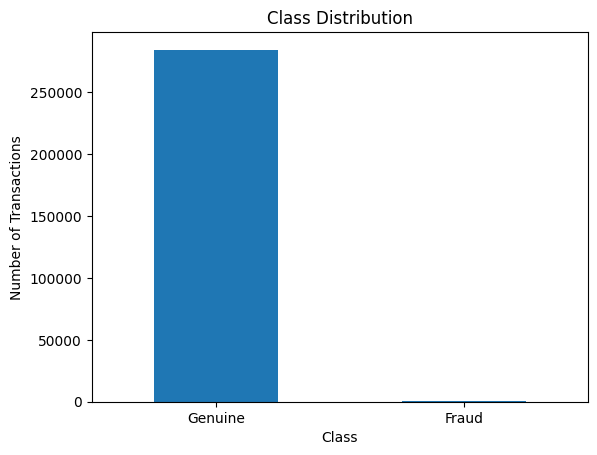

In [16]:
import matplotlib.pyplot as plt

class_counts.plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Genuine", "Fraud"], rotation=0)
plt.show()

In [17]:
print(df["Amount"].describe())

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64


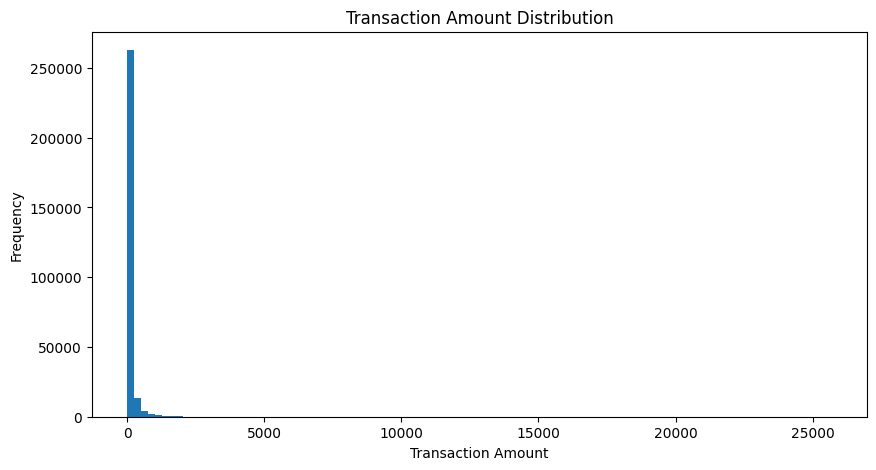

In [18]:
plt.figure(figsize=(10, 5))

plt.hist(df["Amount"], bins=100)

plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Transaction Amount Distribution")

plt.show()

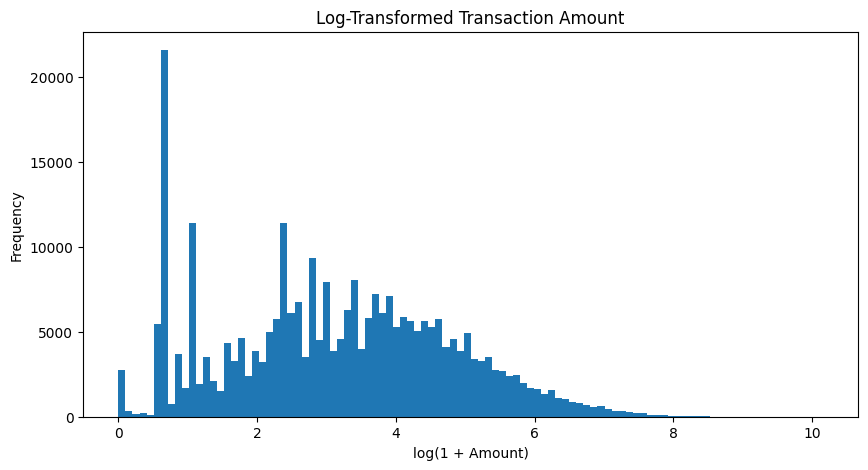

In [19]:
import numpy as np

plt.figure(figsize=(10, 5))

plt.hist(np.log1p(df["Amount"]), bins=100)

plt.xlabel("log(1 + Amount)")
plt.ylabel("Frequency")
plt.title("Log-Transformed Transaction Amount")

plt.show()

In [20]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


/tmp/ipykernel_675/914196895.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


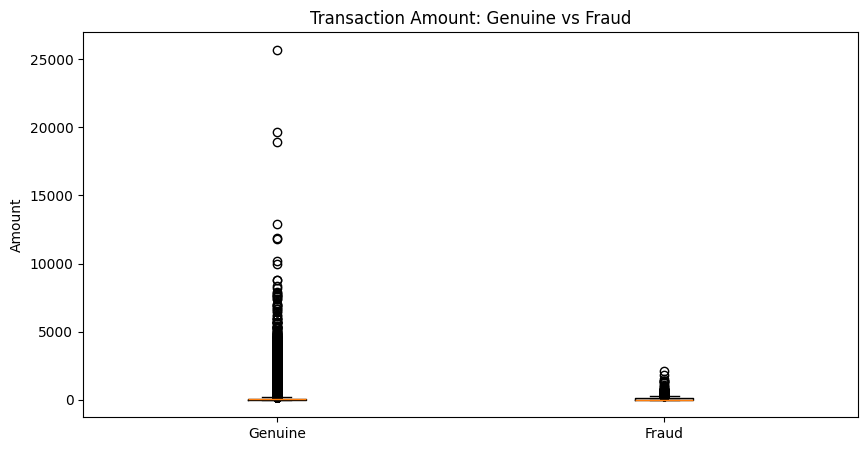

In [21]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    [
        df[df["Class"] == 0]["Amount"],
        df[df["Class"] == 1]["Amount"]
    ],
    labels=["Genuine", "Fraud"]
)

plt.ylabel("Amount")
plt.title("Transaction Amount: Genuine vs Fraud")

plt.show()

In [22]:
print(df["Time"].describe())

count    284807.000000
mean      94813.859575
std       47488.145955
min           0.000000
25%       54201.500000
50%       84692.000000
75%      139320.500000
max      172792.000000
Name: Time, dtype: float64


In [23]:
df["Hour"] = (df["Time"] / 3600) % 24

df[["Time", "Hour", "Class"]].head()

,Time,Hour,Class
0,0.0,0.000000,0
1,0.0,0.000000,0
2,1.0,0.000278,0
3,1.0,0.000278,0
4,2.0,0.000556,0


In [24]:
hourly_fraud = df.groupby("Hour")["Class"].agg(
    transactions="count",
    frauds="sum"
)

hourly_fraud["fraud_rate"] = (
    hourly_fraud["frauds"] / hourly_fraud["transactions"] * 100
)

hourly_fraud.head(24)

,transactions,frauds,fraud_rate
Hour,,,
0.000000,3,0,0.0
0.000278,2,0,0.0
0.000278,4,0,0.0
0.000556,3,0,0.0
0.000556,2,0,0.0
0.000833,1,0,0.0
0.001111,1,0,0.0
0.001111,1,0,0.0
0.001389,1,0,0.0


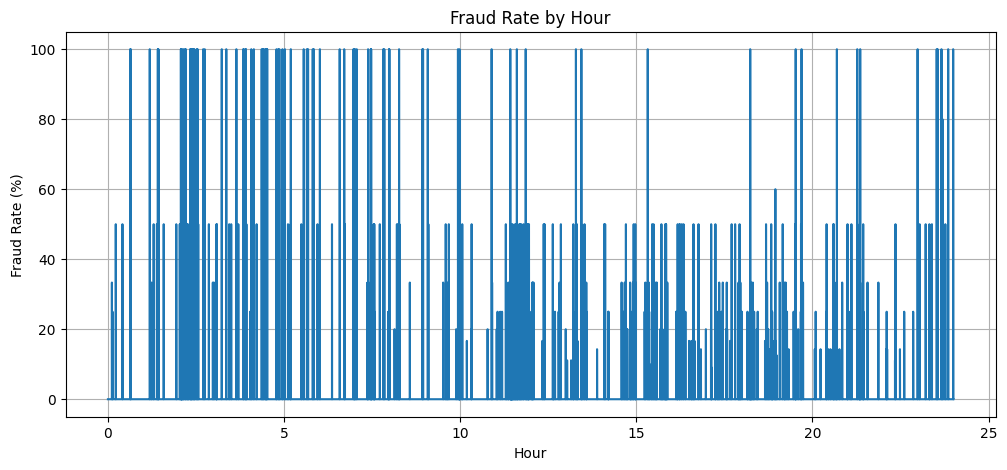

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_fraud.index,
    hourly_fraud["fraud_rate"]
)

plt.xlabel("Hour")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Hour")
plt.grid()

plt.show()

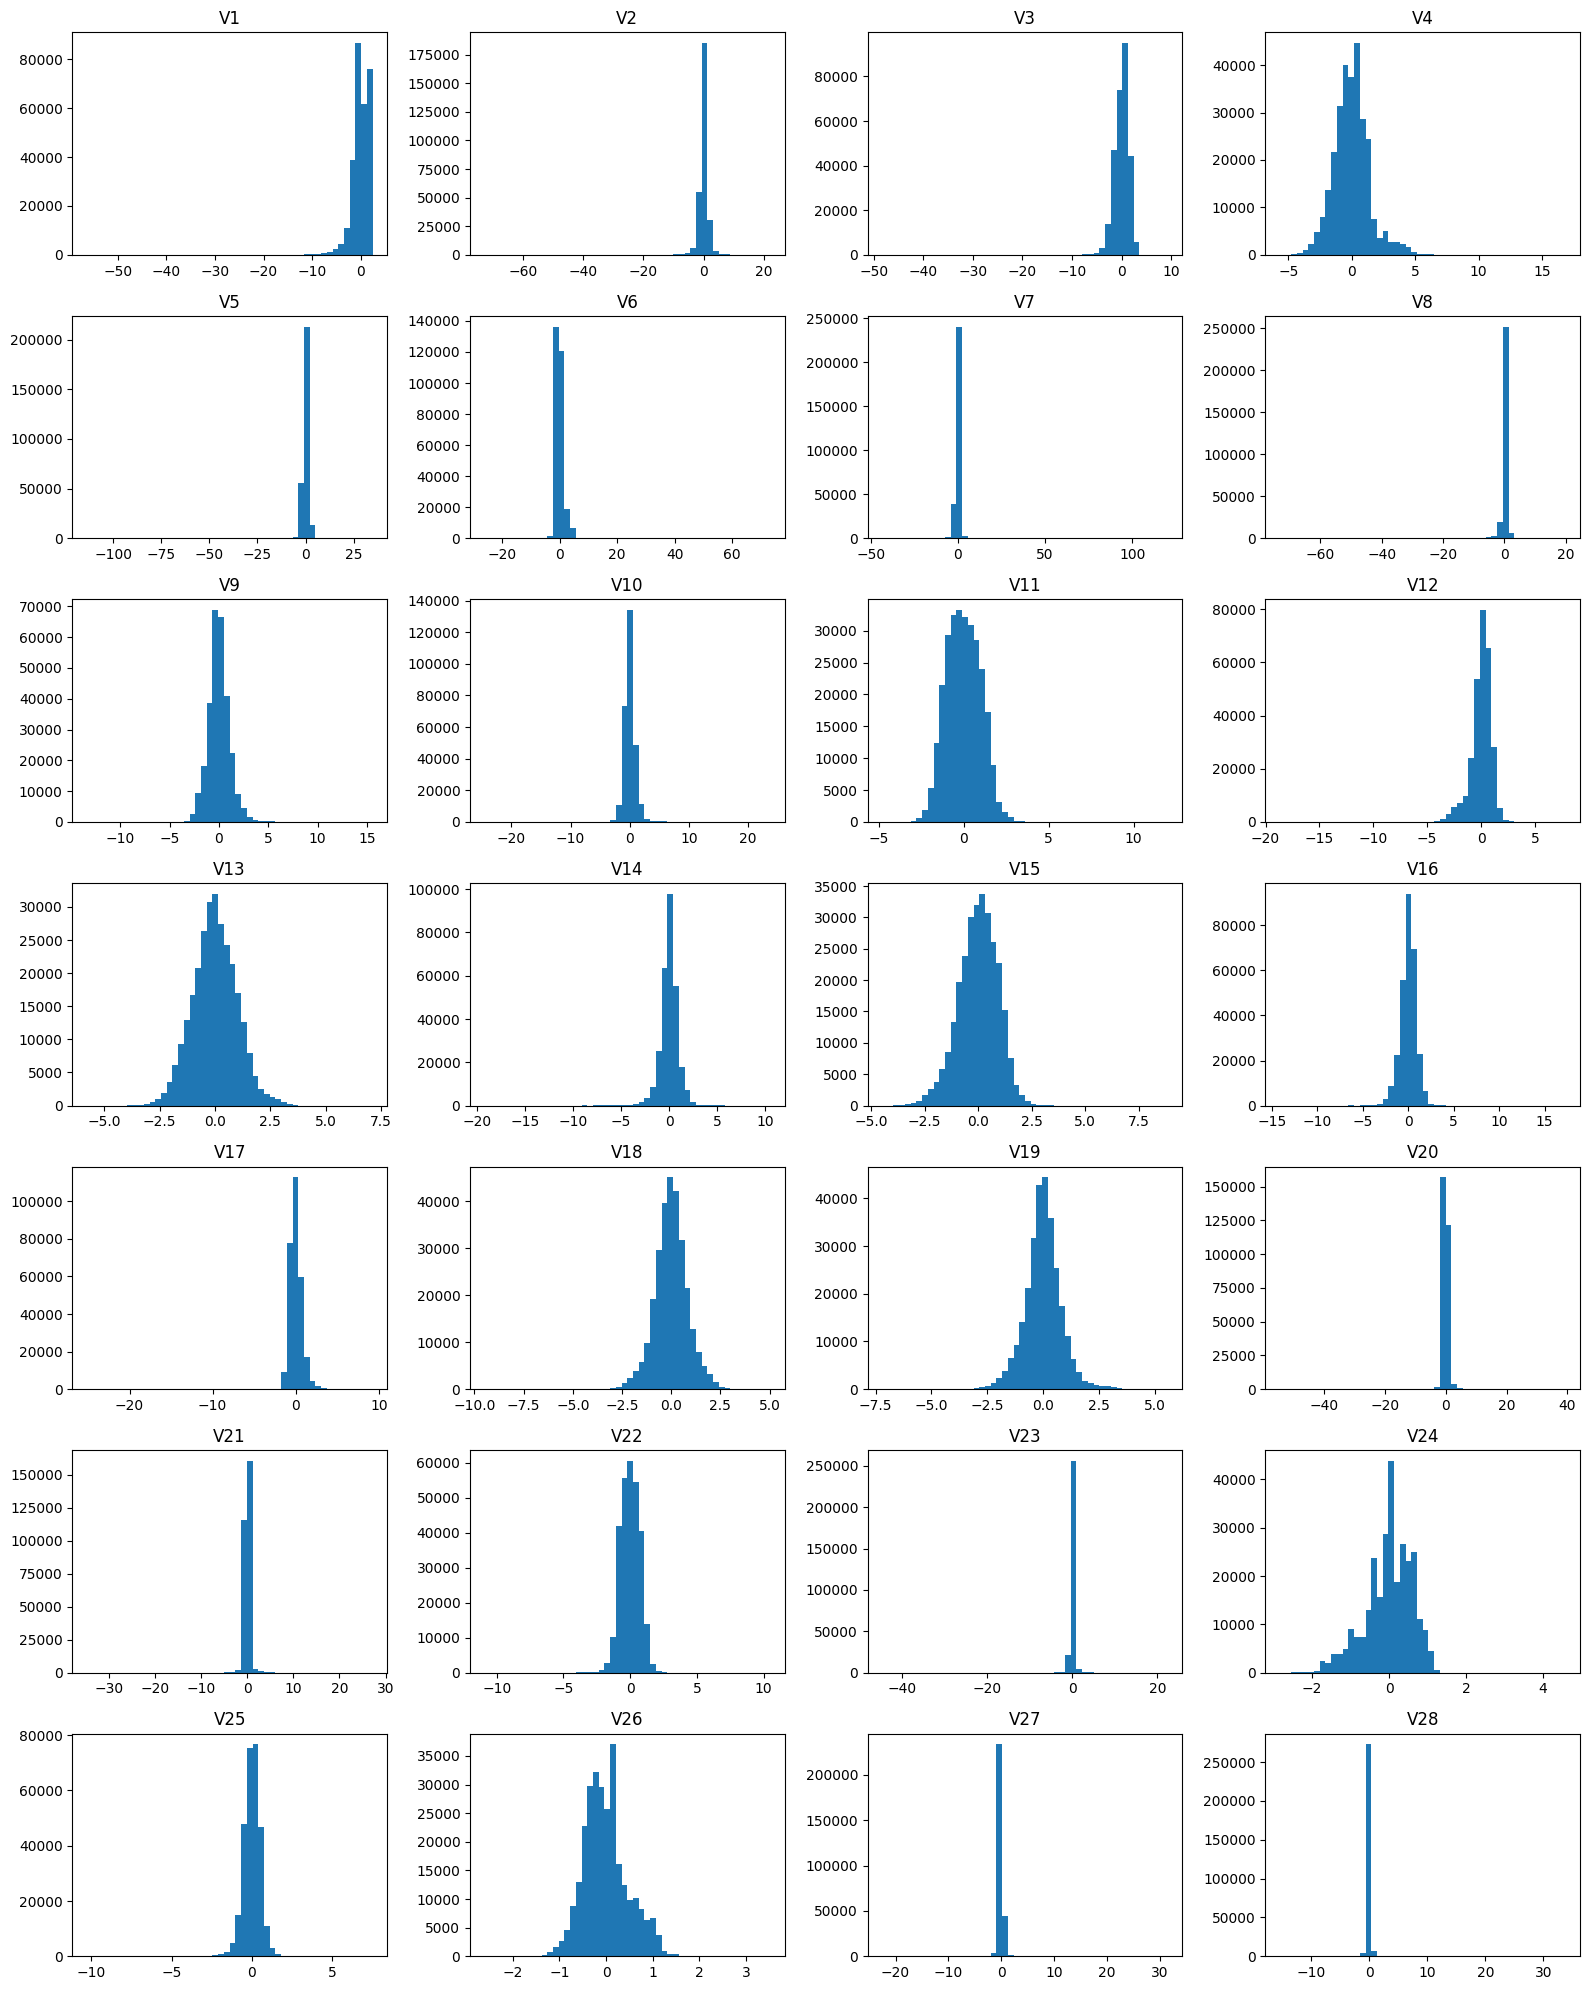

In [26]:
fig, axes = plt.subplots(7, 4, figsize=(16, 20))

for i, col in enumerate([f"V{i}" for i in range(1, 29)]):
    axes.flat[i].hist(df[col], bins=50)
    axes.flat[i].set_title(col)

plt.tight_layout()
plt.show()

In [27]:
correlations = df.corr(numeric_only=True)["Class"].sort_values(
    key=abs,
    ascending=False
)

print(correlations)

Class     1.000000
V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V11       0.154876
V4        0.133447
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V2        0.091289
V6       -0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Hour     -0.017082
Time     -0.012323
V28       0.009536
V24      -0.007221
Amount    0.005632
V13      -0.004570
V26       0.004455
V15      -0.004223
V25       0.003308
V23      -0.002685
V22       0.000805
Name: Class, dtype: float64


In [28]:
correlations.head(10)

,Class
Class,1.000000
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V11,0.154876
V4,0.133447


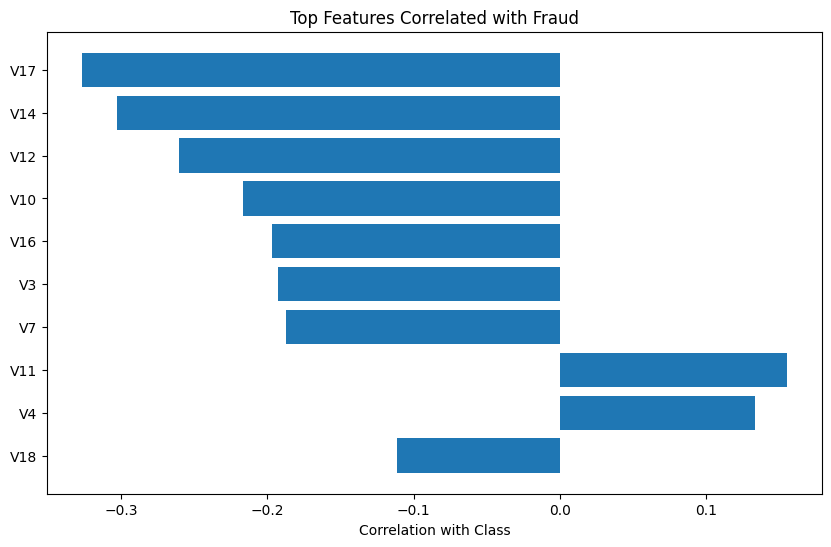

In [29]:
top_features = correlations.index[1:11]

plt.figure(figsize=(10, 6))

plt.barh(
    top_features[::-1],
    correlations[top_features][::-1]
)

plt.xlabel("Correlation with Class")
plt.title("Top Features Correlated with Fraud")

plt.show()

In [30]:
# How many duplicated rows are there?
print("Duplicate rows:", df.duplicated().sum())

# How many unique rows?
print("Unique rows:", df.drop_duplicates().shape[0])

Duplicate rows: 1081
Unique rows: 283726


In [31]:
# Look only at duplicated rows
dupes = df[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
)

print("Total rows involved in duplicate groups:", len(dupes))

# Check class distribution among duplicated rows
print(dupes["Class"].value_counts())

Total rows involved in duplicate groups: 1854
Class
0    1822
1      32
Name: count, dtype: int64


In [32]:
feature_cols = [col for col in df.columns if col != "Class"]

duplicate_label_check = (
    df.groupby(feature_cols)["Class"]
      .nunique()
)

print(
    "Duplicate feature groups with conflicting Class labels:",
    (duplicate_label_check > 1).sum()
)

Duplicate feature groups with conflicting Class labels: 0


In [33]:
df_unique = df.drop_duplicates()

print("Original shape:", df.shape)
print("After deduplication:", df_unique.shape)

print("\nOriginal class distribution:")
print(df["Class"].value_counts())

print("\nAfter deduplication:")
print(df_unique["Class"].value_counts())

print("\nFraud rate after deduplication:")
print(df_unique["Class"].mean() * 100)

Original shape: (284807, 32)
After deduplication: (283726, 32)

Original class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

After deduplication:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud rate after deduplication:
0.1667101358352777


In [34]:
print(
    "Fraud duplicates:",
    df[df.duplicated(keep=False) & (df["Class"] == 1)].shape[0]
)

Fraud duplicates: 32


In [36]:
# Create clean dataset by removing exact duplicate rows
df_clean = df.drop_duplicates().copy()

print("Original shape:", df.shape)
print("Clean shape:", df_clean.shape)

print("\nClass distribution:")
print(df_clean["Class"].value_counts())

print("\nClass percentage:")
print(df_clean["Class"].value_counts(normalize=True) * 100)

Original shape: (284807, 32)
Clean shape: (283726, 32)

Class distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Class percentage:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


In [37]:
print(df_clean.groupby("Class")["Amount"].describe())

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


In [38]:
correlations = (
    df_clean
    .corr(numeric_only=True)["Class"]
    .sort_values(key=abs, ascending=False)
)

print(correlations.head(11))

Class    1.000000
V17     -0.313498
V14     -0.293375
V12     -0.250711
V10     -0.206971
V16     -0.187186
V3      -0.182322
V7      -0.172347
V11      0.149067
V4       0.129326
V18     -0.105340
Name: Class, dtype: float64


In [39]:
amount_stats = df_clean.groupby("Class")["Amount"].describe()
amount_stats

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


In [40]:
print("Genuine median:",
      df_clean[df_clean["Class"] == 0]["Amount"].median())

print("Fraud median:",
      df_clean[df_clean["Class"] == 1]["Amount"].median())

print("Genuine mean:",
      df_clean[df_clean["Class"] == 0]["Amount"].mean())

print("Fraud mean:",
      df_clean[df_clean["Class"] == 1]["Amount"].mean())

Genuine median: 22.0
Fraud median: 9.82
Genuine mean: 88.41357475472456
Fraud mean: 123.87186046511628


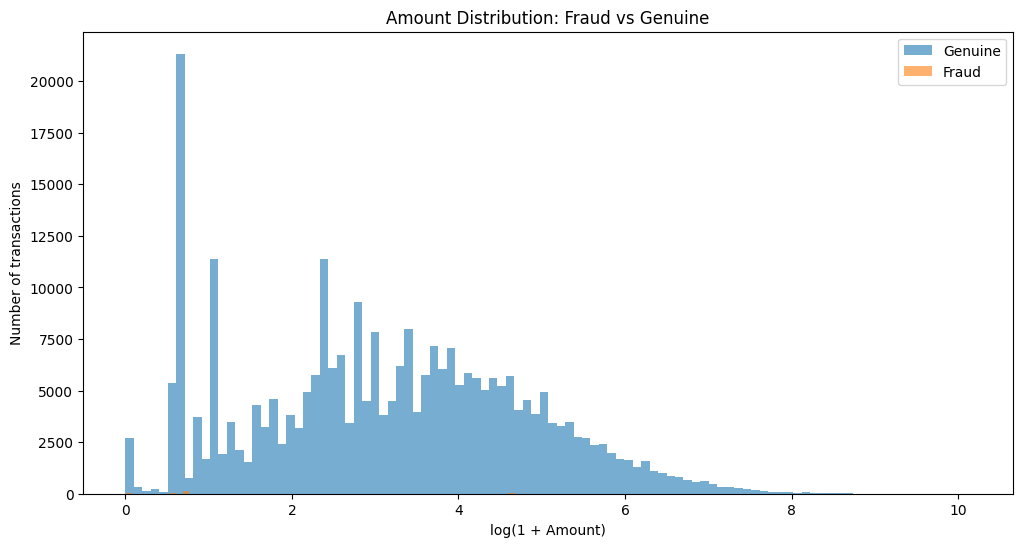

In [41]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.hist(
    np.log1p(df_clean.loc[df_clean["Class"] == 0, "Amount"]),
    bins=100,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    np.log1p(df_clean.loc[df_clean["Class"] == 1, "Amount"]),
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("log(1 + Amount)")
plt.ylabel("Number of transactions")
plt.title("Amount Distribution: Fraud vs Genuine")
plt.legend()

plt.show()

In [42]:
df_clean["Time"].describe()

,Time
count,283726.000000
mean,94811.077600
std,47481.047891
min,0.000000
25%,54204.750000
50%,84692.500000
75%,139298.000000
max,172792.000000


In [43]:
df_clean["Hour"] = (df_clean["Time"] / 3600) % 24

In [44]:
hour_analysis = df_clean.groupby("Hour")["Class"].agg(
    transactions="count",
    frauds="sum"
)

hour_analysis["fraud_rate"] = (
    hour_analysis["frauds"] /
    hour_analysis["transactions"]
) * 100

hour_analysis

,transactions,frauds,fraud_rate
Hour,,,
0.000000,3,0,0.0
0.000278,2,0,0.0
0.000278,4,0,0.0
0.000556,3,0,0.0
0.000556,2,0,0.0
...,...,...,...
23.997222,1,0,0.0
23.997778,3,0,0.0
23.998333,1,0,0.0


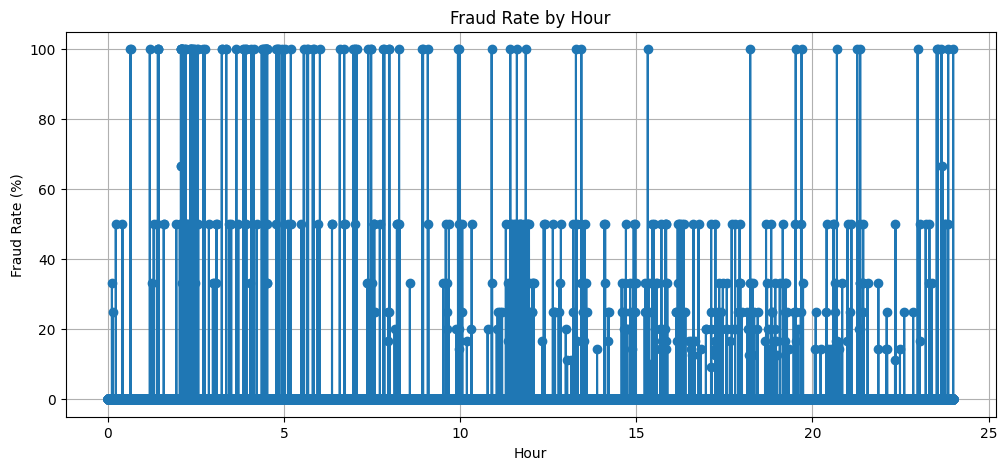

In [45]:
plt.figure(figsize=(12, 5))

plt.plot(
    hour_analysis.index,
    hour_analysis["fraud_rate"],
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Fraud Rate (%)")
plt.title("Fraud Rate by Hour")
plt.grid()

plt.show()

In [46]:
correlations = (
    df_clean
    .corr(numeric_only=True)["Class"]
    .sort_values(key=abs, ascending=False)
)

print(correlations.head(11))

Class    1.000000
V17     -0.313498
V14     -0.293375
V12     -0.250711
V10     -0.206971
V16     -0.187186
V3      -0.182322
V7      -0.172347
V11      0.149067
V4       0.129326
V18     -0.105340
Name: Class, dtype: float64


In [47]:
top_feature = correlations.index[1]

print("Strongest feature:", top_feature)
print("Correlation:", correlations[top_feature])

Strongest feature: V17
Correlation: -0.3134982729556793


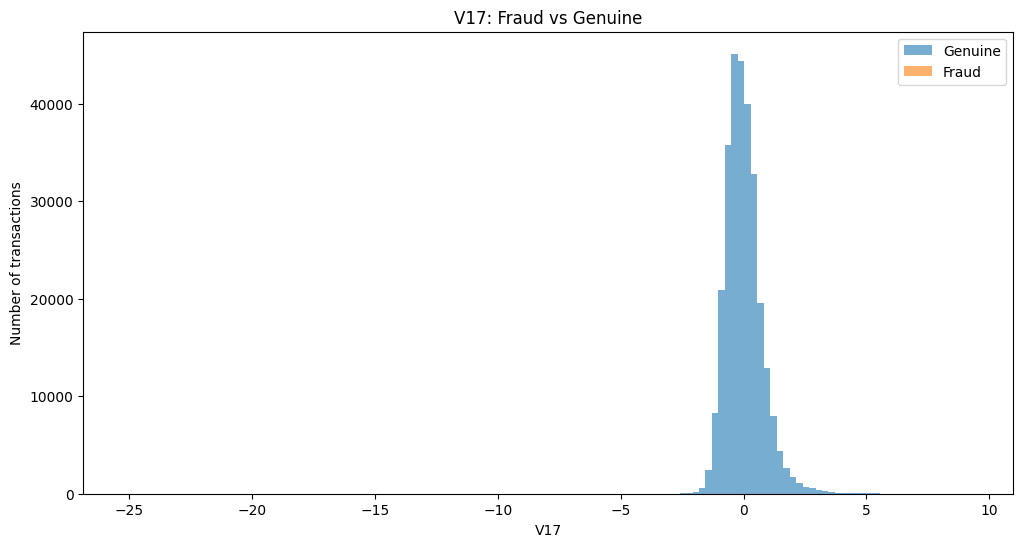

In [48]:
feature = top_feature

plt.figure(figsize=(12, 6))

plt.hist(
    df_clean.loc[df_clean["Class"] == 0, feature],
    bins=100,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    df_clean.loc[df_clean["Class"] == 1, feature],
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel(feature)
plt.ylabel("Number of transactions")
plt.title(f"{feature}: Fraud vs Genuine")
plt.legend()

plt.show()

In [49]:
v_features = [f"V{i}" for i in range(1, 29)]

comparison = pd.DataFrame({
    "genuine_mean": df_clean[df_clean["Class"] == 0][v_features].mean(),
    "fraud_mean": df_clean[df_clean["Class"] == 1][v_features].mean(),
})

comparison["difference"] = (
    comparison["fraud_mean"] -
    comparison["genuine_mean"]
)

comparison["abs_difference"] = comparison["difference"].abs()

comparison.sort_values(
    "abs_difference",
    ascending=False
)

,genuine_mean,fraud_mean,difference,abs_difference
V14,0.011668,-6.835946,-6.847614,6.847614
V3,0.012853,-6.729599,-6.742452,6.742452
V17,0.010963,-6.463285,-6.474249,6.474249
V12,0.009476,-6.103254,-6.112730,6.112730
V10,0.007663,-5.453274,-5.460937,5.460937
V7,0.010447,-5.175912,-5.186359,5.186359
V1,0.013439,-4.498280,-4.511719,4.511719
V4,-0.010440,4.472591,4.483031,4.483031
V16,0.007845,-4.000956,-4.008801,4.008801
V11,-0.006004,3.716347,3.722350,3.722350


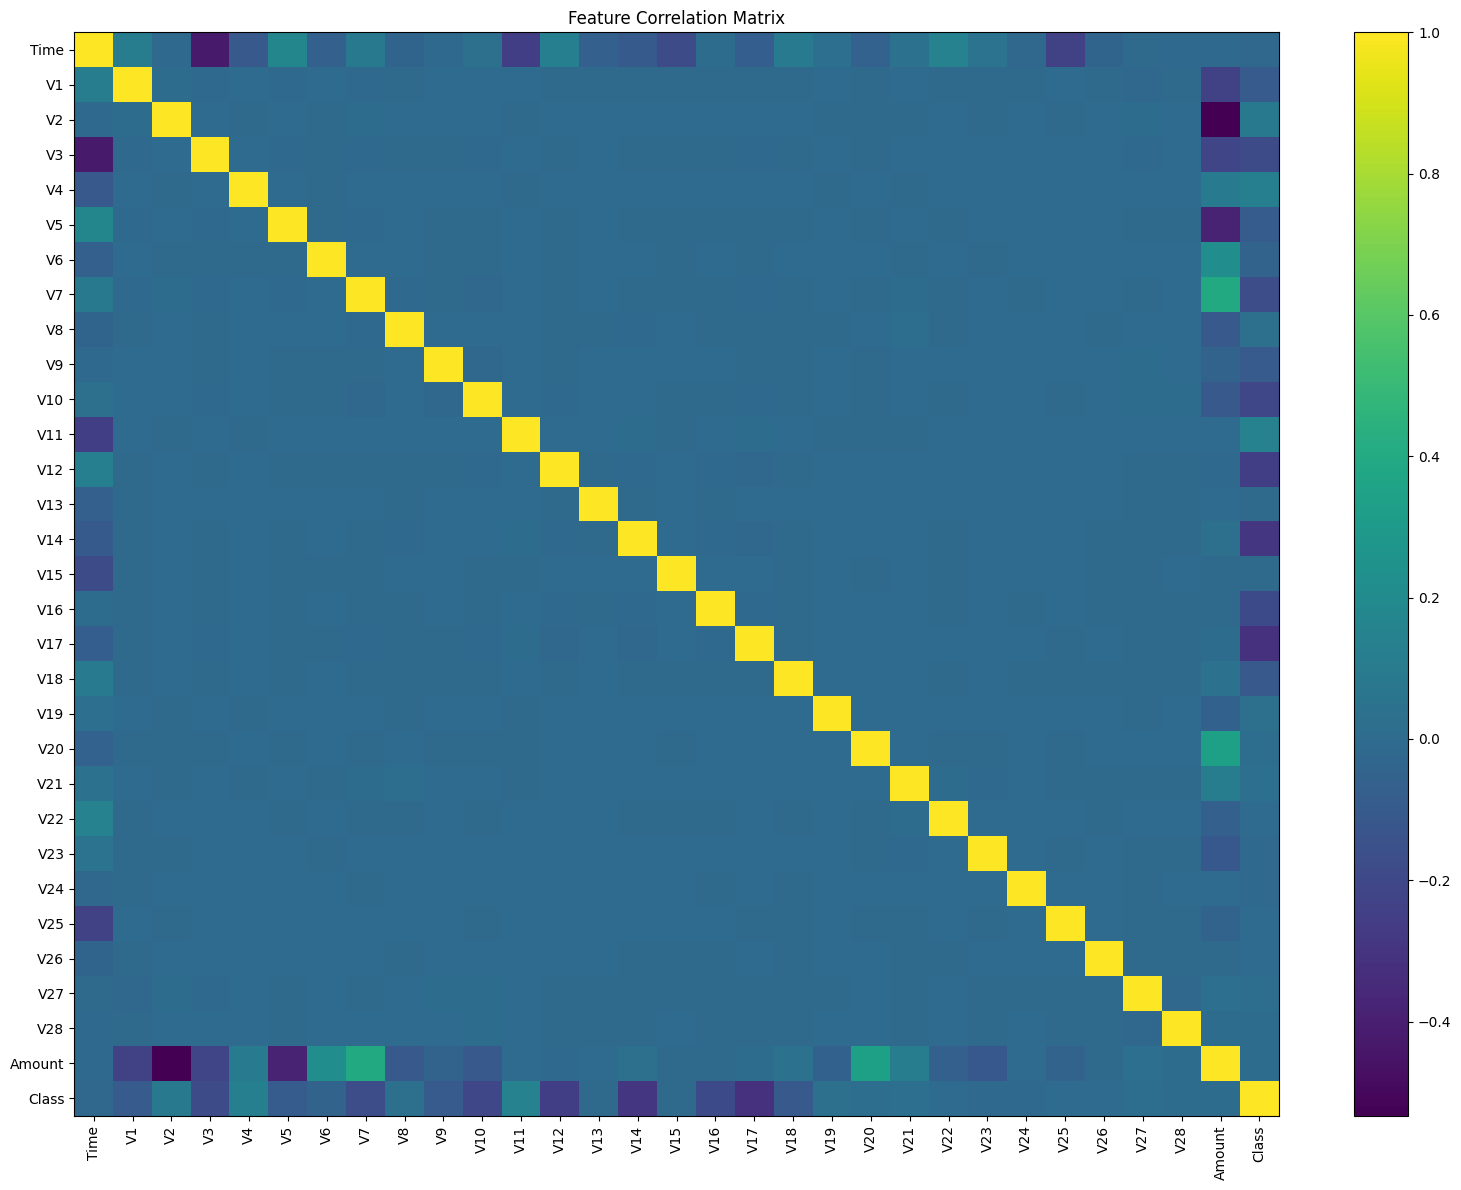

In [51]:
plt.figure(figsize=(16, 12))

corr_matrix = df_clean.drop(columns=["Hour"]).corr()

plt.imshow(corr_matrix, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()

plt.show()

In [52]:
# Features and target
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFraud rate:")
print(y.mean() * 100)

X shape: (283726, 31)
y shape: (283726,)

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64

Fraud rate:
0.1667101358352777


In [54]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

In [55]:
def dataset_summary(name, X_data, y_data):
    print(f"\n{name}")
    print("-" * 40)
    print("Samples:", len(X_data))
    print("Frauds:", y_data.sum())
    print("Genuine:", (y_data == 0).sum())
    print("Fraud rate:", f"{y_data.mean() * 100:.4f}%")

dataset_summary("TRAIN", X_train, y_train)
dataset_summary("VALIDATION", X_val, y_val)
dataset_summary("TEST", X_test, y_test)


TRAIN
----------------------------------------
Samples: 226980
Frauds: 378
Genuine: 226602
Fraud rate: 0.1665%

VALIDATION
----------------------------------------
Samples: 28373
Frauds: 48
Genuine: 28325
Fraud rate: 0.1692%

TEST
----------------------------------------
Samples: 28373
Frauds: 47
Genuine: 28326
Fraud rate: 0.1657%


In [56]:
train_idx = set(X_train.index)
val_idx = set(X_val.index)
test_idx = set(X_test.index)

print("Train ∩ Validation:", len(train_idx & val_idx))
print("Train ∩ Test:", len(train_idx & test_idx))
print("Validation ∩ Test:", len(val_idx & test_idx))

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


In [58]:
scaler.fit_transform(X_train)

array([[ 1.04549909e+00,  1.14719836e+00, -1.04203246e+00, ...,
        -1.56192658e-01, -2.29433724e-01,  2.75087818e-01],
       [-2.98690019e-01, -6.77911305e-01,  9.91948465e-01, ...,
         1.53831425e-01, -3.31196981e-01,  1.34855957e+00],
       [ 6.78396673e-01,  9.77653618e-01,  1.62053993e-02, ...,
        -1.65819856e-01, -2.98808515e-01, -5.54168757e-01],
       ...,
       [ 1.19385202e+00, -4.52142124e-01,  7.06553792e-01, ...,
         2.88355918e-01, -2.09089210e-01,  6.10205845e-01],
       [-9.58244594e-01,  6.37814459e-01,  2.14682857e-01, ...,
         9.53313823e-02, -3.39294097e-01, -1.41324277e-01],
       [-8.96102723e-01,  5.23616867e-01, -1.32163174e-01, ...,
        -7.09689617e-03, -3.09550419e-01, -9.50494868e-04]])

In [59]:
print("Train scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)

print("\nTrain mean:")
print(X_train_scaled.mean(axis=0)[:5])

print("\nTrain std:")
print(X_train_scaled.std(axis=0)[:5])

Train scaled shape: (226980, 31)
Validation scaled shape: (28373, 31)
Test scaled shape: (28373, 31)

Train mean:
[-1.51887979e-16  1.62781841e-18 -1.22086381e-17  8.17039625e-18
 -2.65772660e-17]

Train std:
[1. 1. 1. 1. 1.]


In [61]:
import joblib

joblib.dump(scaler, "fraud_scaler.pkl")

joblib.dump(
    {
        "X_train": X_train_scaled,
        "X_val": X_val_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    },
    "fraud_splits.pkl"
)

print("Saved successfully.")

Saved successfully.


In [62]:
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

print("Baseline model trained.")

Baseline model trained.


Why Logistic Regression?

Conceptually:

$$ P(Fraud|X) = \sigma(w^TX+b) $$

It learns a weighted combination of the transaction features and outputs a probability of fraud.

This gives us a very important baseline:

Features
   ↓
Linear decision boundary
   ↓
Fraud probability

Later we'll compare this against nonlinear models.

In [63]:
y_val_pred = baseline_model.predict(X_val_scaled)

In [64]:
y_val_proba = baseline_model.predict_proba(X_val_scaled)[:, 1]

In [65]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, digits=4))

Confusion Matrix:
[[28321     4]
 [   22    26]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9992    0.9999    0.9995     28325
           1     0.8667    0.5417    0.6667        48

    accuracy                         0.9991     28373
   macro avg     0.9329    0.7708    0.8331     28373
weighted avg     0.9990    0.9991    0.9990     28373



In [66]:
precision = precision_score(y_val, y_val_pred)
recall = recall_score(y_val, y_val_pred)
f1 = f1_score(y_val, y_val_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

Precision: 0.8666666666666667
Recall: 0.5416666666666666
F1: 0.6666666666666666


In [67]:
from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_val, y_val_proba)
pr_auc = average_precision_score(y_val, y_val_proba)

print("ROC-AUC:", roc_auc)
print("PR-AUC / AUPRC:", pr_auc)

ROC-AUC: 0.9314724919093852
PR-AUC / AUPRC: 0.6370669816765189


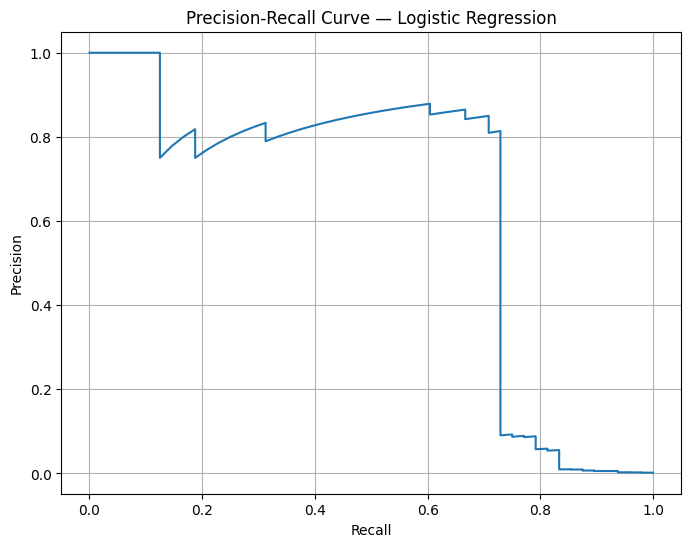

In [68]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision_curve, recall_curve, thresholds = precision_recall_curve(
    y_val,
    y_val_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Logistic Regression")
plt.grid(True)

plt.show()

In [69]:
import pandas as pd

prediction_analysis = pd.DataFrame({
    "actual": y_val.values,
    "probability": y_val_proba
})

prediction_analysis.sort_values(
    "probability",
    ascending=False
).head(20)

,actual,probability
7148,1,1.000000
8945,1,1.000000
5249,1,1.000000
15537,1,1.000000
21770,1,1.000000
10022,1,0.999999
7041,0,0.999972
9983,0,0.999912
28137,1,0.999529
21871,1,0.999245


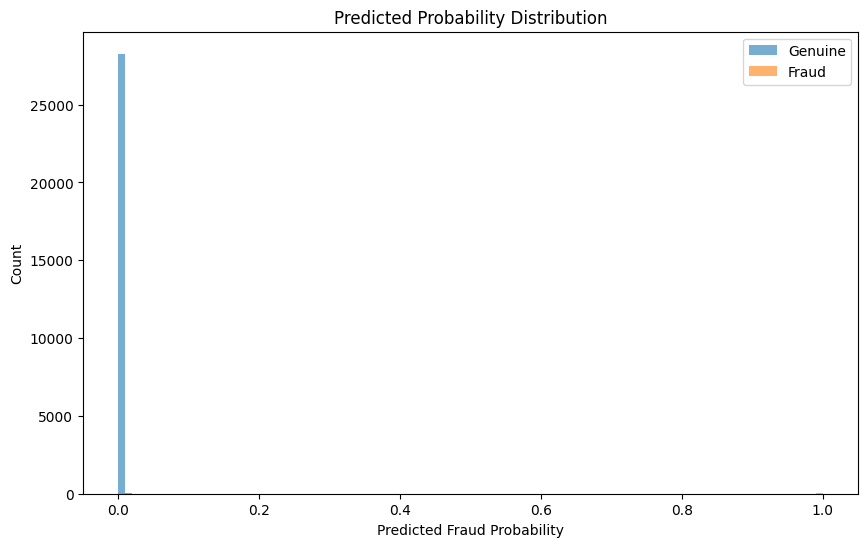

In [70]:
plt.figure(figsize=(10, 6))

plt.hist(
    y_val_proba[y_val.values == 0],
    bins=100,
    alpha=0.6,
    label="Genuine"
)

plt.hist(
    y_val_proba[y_val.values == 1],
    bins=100,
    alpha=0.6,
    label="Fraud"
)

plt.xlabel("Predicted Fraud Probability")
plt.ylabel("Count")
plt.title("Predicted Probability Distribution")
plt.legend()
plt.show()

In [72]:
baseline_results = {
    "model": "Logistic Regression",
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "roc_auc": roc_auc,
    "pr_auc": pr_auc
}

baseline_results

{'model': 'Logistic Regression',
 'precision': 0.8666666666666667,
 'recall': 0.5416666666666666,
 'f1': 0.6666666666666666,
 'roc_auc': np.float64(0.9314724919093852),
 'pr_auc': np.float64(0.6370669816765189)}

Strong Classical ML: Tree-Based Models

Now we move from a linear decision boundary to nonlinear feature interactions.

Your Logistic Regression assumes roughly:

$$ \text{logit}(P(Fraud)) = w_0+w_1X_1+\cdots+w_nX_n $$

But fraud patterns can involve interactions such as:

V17 + V14 + V12 + Amount

rather than each feature independently determining fraud.

We'll test Random Forest first, then move to a gradient-boosting model.

In [73]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained.")

Random Forest trained.


In [74]:
y_val_rf_proba = rf_model.predict_proba(X_val)[:, 1]

y_val_rf_pred = (y_val_rf_proba >= 0.5).astype(int)

In [75]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

rf_precision = precision_score(y_val, y_val_rf_pred)
rf_recall = recall_score(y_val, y_val_rf_pred)
rf_f1 = f1_score(y_val, y_val_rf_pred)

rf_roc_auc = roc_auc_score(y_val, y_val_rf_proba)
rf_pr_auc = average_precision_score(y_val, y_val_rf_proba)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_rf_pred))

print("\nPrecision:", rf_precision)
print("Recall:", rf_recall)
print("F1:", rf_f1)
print("ROC-AUC:", rf_roc_auc)
print("PR-AUC:", rf_pr_auc)

Confusion Matrix:
[[28324     1]
 [   14    34]]

Precision: 0.9714285714285714
Recall: 0.7083333333333334
F1: 0.8192771084337349
ROC-AUC: 0.9226003971756398
PR-AUC: 0.765758587063282


In [76]:
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    },
    {
        "Model": "Random Forest",
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1,
        "ROC-AUC": rf_roc_auc,
        "PR-AUC": rf_pr_auc
    }
])

comparison

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.866667,0.541667,0.666667,0.931472,0.637067
1,Random Forest,0.971429,0.708333,0.819277,0.922600,0.765759


In [77]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance.head(15)

,0
V17,0.149238
V12,0.135484
V14,0.123744
V10,0.086863
V11,0.064675
V16,0.061667
V9,0.038424
V7,0.028406
V18,0.027994
V4,0.026341


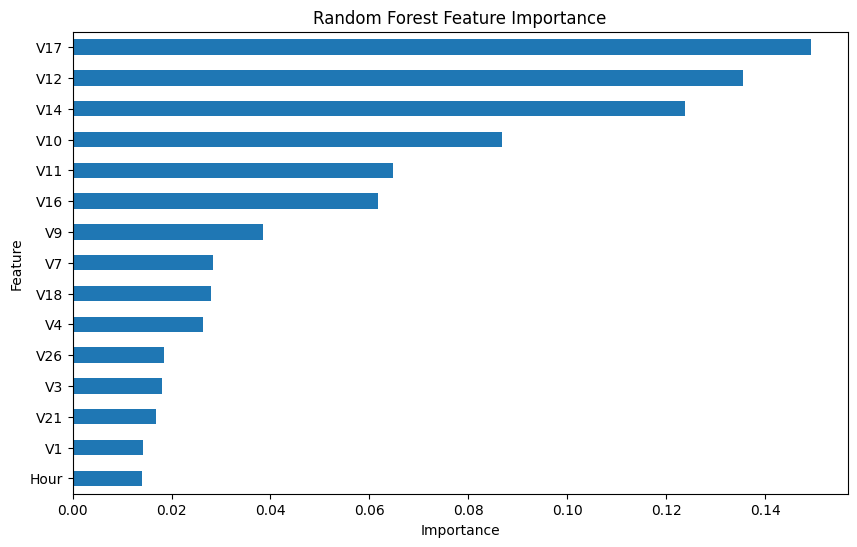

In [78]:
plt.figure(figsize=(10, 6))

feature_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.show()

In [79]:
print("Top RF features:")
print(feature_importance.head(15))

Top RF features:
V17     0.149238
V12     0.135484
V14     0.123744
V10     0.086863
V11     0.064675
V16     0.061667
V9      0.038424
V7      0.028406
V18     0.027994
V4      0.026341
V26     0.018381
V3      0.018123
V21     0.016914
V1      0.014226
Hour    0.013965
dtype: float64


In [80]:
!pip install -q xgboost

In [81]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost trained.")

XGBoost trained.


In [82]:
eval_metric="aucpr"

In [83]:
y_val_xgb_proba = xgb_model.predict_proba(X_val)[:, 1]

y_val_xgb_pred = (y_val_xgb_proba >= 0.5).astype(int)

xgb_precision = precision_score(y_val, y_val_xgb_pred)
xgb_recall = recall_score(y_val, y_val_xgb_pred)
xgb_f1 = f1_score(y_val, y_val_xgb_pred)

xgb_roc_auc = roc_auc_score(y_val, y_val_xgb_proba)
xgb_pr_auc = average_precision_score(y_val, y_val_xgb_proba)

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_xgb_pred))

print("\nPrecision:", xgb_precision)
print("Recall:", xgb_recall)
print("F1:", xgb_f1)
print("ROC-AUC:", xgb_roc_auc)
print("PR-AUC:", xgb_pr_auc)

Confusion Matrix:
[[28325     0]
 [   13    35]]

Precision: 1.0
Recall: 0.7291666666666666
F1: 0.8433734939759037
ROC-AUC: 0.9656656369520447
PR-AUC: 0.8084769008150575


In [84]:
comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    },
    {
        "Model": "Random Forest",
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1,
        "ROC-AUC": rf_roc_auc,
        "PR-AUC": rf_pr_auc
    },
    {
        "Model": "XGBoost",
        "Precision": xgb_precision,
        "Recall": xgb_recall,
        "F1": xgb_f1,
        "ROC-AUC": xgb_roc_auc,
        "PR-AUC": xgb_pr_auc
    }
])

comparison.sort_values("PR-AUC", ascending=False)

,Model,Precision,Recall,F1,ROC-AUC,PR-AUC
2,XGBoost,1.000000,0.729167,0.843373,0.965666,0.808477
1,Random Forest,0.971429,0.708333,0.819277,0.922600,0.765759
0,Logistic Regression,0.866667,0.541667,0.666667,0.931472,0.637067


What Stage 5 teaches you

You are now comparing three fundamentally different approaches:

                 Model
                   │
        ┌──────────┼──────────┐
        ↓          ↓          ↓
 Logistic       Random      XGBoost
Regression      Forest
        │          │          │
      Linear     Bagging    Boosting
        │          │          │
        └──────────┼──────────┘
                   ↓
             Fraud probability
                   ↓
              PR-AUC

Your current benchmark is:

Logistic Regression → PR-AUC = 0.6371

Now we want to see how much nonlinear modeling improves that.

Stage 6 — Imbalanced Learning

Your current benchmark is:

XGBoost
PR-AUC = 0.8085
Recall  = 72.92%
Precision = 100%

Now we test whether explicitly handling the extreme imbalance improves the model.

Important: validation and test data remain completely untouched. We modify training data only.

ORIGINAL TRAINING DISTRIBUTION
Class
0    226602
1       378
Name: count, dtype: int64

Fraud rate: 0.1665%

MODEL 1 — BASELINE XGBOOST

CLASS WEIGHT
Genuine: 226602
Fraud: 378

scale_pos_weight = 599.48

MODEL 2 — XGBOOST + SCALE_POS_WEIGHT

RANDOM OVERSAMPLING
Before oversampling:
Class
0    226602
1       378
Name: count, dtype: int64

After oversampling:
Class
0    226602
1    226602
Name: count, dtype: int64

MODEL 3 — RANDOM OVERSAMPLING + XGBOOST

SMOTE
Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64

SMOTE training shape: (453204, 31)

MODEL 4 — SMOTE + XGBOOST

STAGE 6 — FINAL COMPARISON


,Model,Threshold,TP,FP,FN,TN,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Baseline XGBoost,0.5,35,0,13,28325,1.000000,0.729167,0.843373,0.965666,0.808477
1,XGBoost + Class Weight,0.5,36,4,12,28321,0.900000,0.750000,0.818182,0.972927,0.800328
2,Random Oversampling + XGBoost,0.5,36,5,12,28320,0.878049,0.750000,0.808989,0.972329,0.795582
3,SMOTE + XGBoost,0.5,37,5,11,28320,0.880952,0.770833,0.822222,0.958307,0.788682


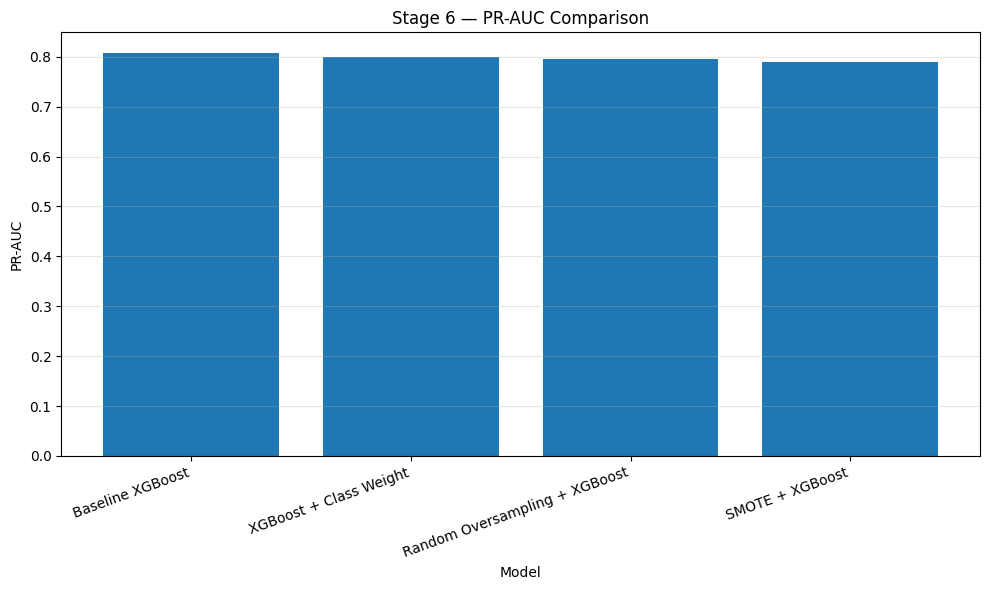

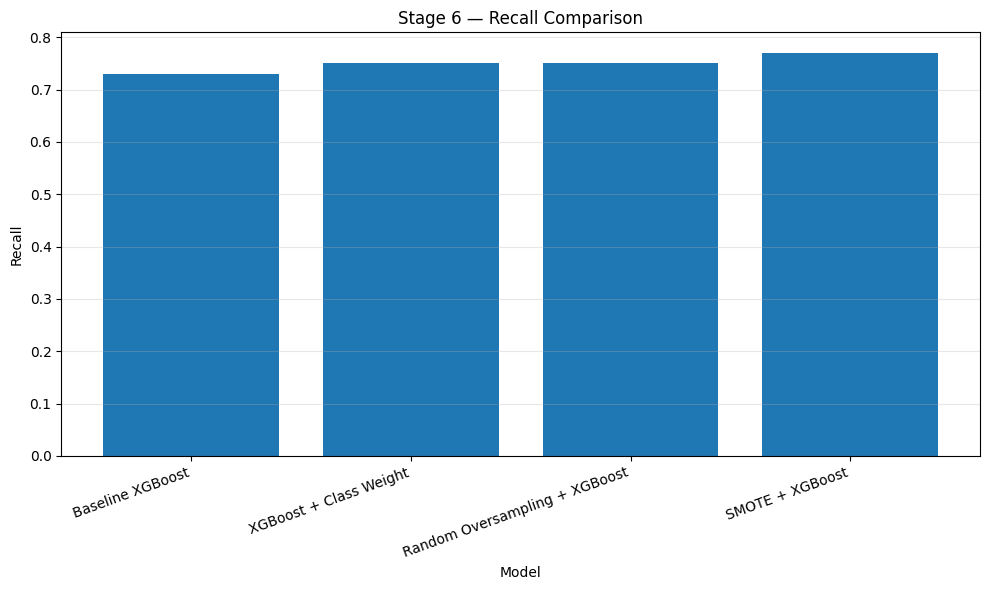

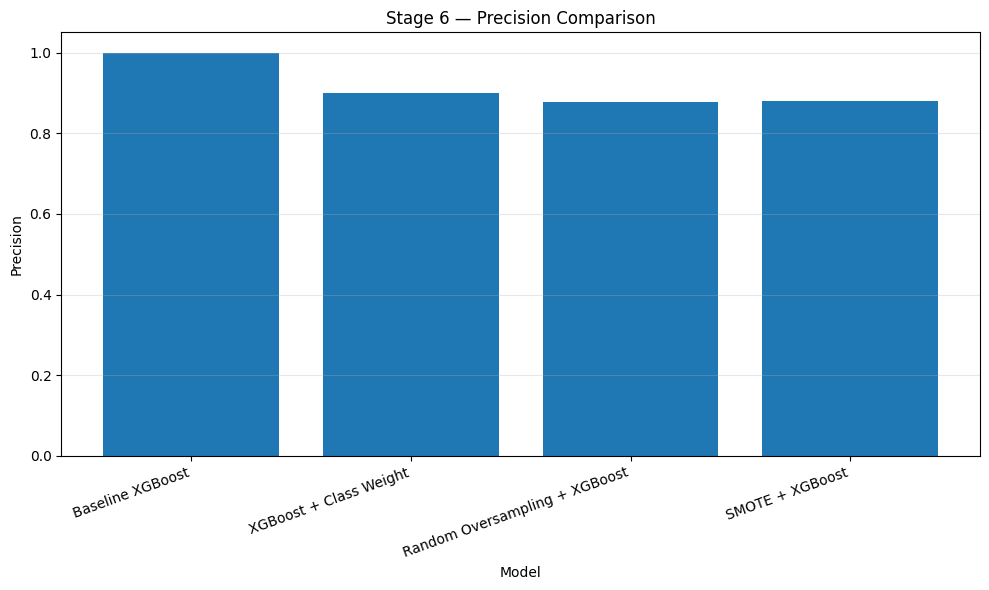


CURRENT BEST MODEL BY PR-AUC
Model     : Baseline XGBoost
PR-AUC    : 0.808477
Precision : 1.000000
Recall    : 0.729167
F1        : 0.843373
ROC-AUC   : 0.965666

LEAKAGE CHECK

Validation data was NEVER oversampled.
Validation data was NEVER used to fit SMOTE.
Validation data was NEVER used to calculate class weights.
All imbalance techniques were applied ONLY to the training set.



In [85]:
# ============================================================
# STAGE 6 — IMBALANCED LEARNING
# Credit Card Fraud Detection
# ============================================================

# ------------------------------------------------------------
# 0. INSTALL DEPENDENCIES
# ------------------------------------------------------------

!pip install -q imbalanced-learn xgboost


# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

from imblearn.over_sampling import RandomOverSampler, SMOTE


# ------------------------------------------------------------
# 2. CHECK ORIGINAL TRAINING DISTRIBUTION
# ------------------------------------------------------------

print("=" * 70)
print("ORIGINAL TRAINING DISTRIBUTION")
print("=" * 70)

print(y_train.value_counts())
print()

print(
    f"Fraud rate: {y_train.mean() * 100:.4f}%"
)


# ------------------------------------------------------------
# 3. BASELINE XGBOOST
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 1 — BASELINE XGBOOST")
print("=" * 70)

xgb_baseline = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_baseline.fit(
    X_train,
    y_train
)

baseline_proba = xgb_baseline.predict_proba(X_val)[:, 1]
baseline_pred = (baseline_proba >= 0.5).astype(int)


# ------------------------------------------------------------
# 4. CALCULATE BASELINE METRICS
# ------------------------------------------------------------

results = []

def evaluate_model(name, y_true, y_proba, threshold=0.5):

    y_pred = (y_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        y_proba
    )

    pr_auc = average_precision_score(
        y_true,
        y_proba
    )

    results.append({
        "Model": name,
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })


evaluate_model(
    "Baseline XGBoost",
    y_val,
    baseline_proba
)


# ------------------------------------------------------------
# 5. CALCULATE SCALE_POS_WEIGHT
# ------------------------------------------------------------

negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("\n" + "=" * 70)
print("CLASS WEIGHT")
print("=" * 70)

print("Genuine:", negative_count)
print("Fraud:", positive_count)

print(
    f"\nscale_pos_weight = {scale_pos_weight:.2f}"
)


# ------------------------------------------------------------
# 6. XGBOOST + CLASS WEIGHT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 2 — XGBOOST + SCALE_POS_WEIGHT")
print("=" * 70)

xgb_weighted = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    scale_pos_weight=scale_pos_weight,

    objective="binary:logistic",
    eval_metric="aucpr",

    random_state=42,
    n_jobs=-1
)

xgb_weighted.fit(
    X_train,
    y_train
)

weighted_proba = xgb_weighted.predict_proba(
    X_val
)[:, 1]

weighted_pred = (
    weighted_proba >= 0.5
).astype(int)

evaluate_model(
    "XGBoost + Class Weight",
    y_val,
    weighted_proba
)


# ------------------------------------------------------------
# 7. RANDOM OVERSAMPLING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RANDOM OVERSAMPLING")
print("=" * 70)

ros = RandomOverSampler(
    sampling_strategy=1.0,
    random_state=42
)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train,
    y_train
)

print("Before oversampling:")
print(y_train.value_counts())

print("\nAfter oversampling:")
print(y_train_ros.value_counts())


# ------------------------------------------------------------
# 8. XGBOOST + RANDOM OVERSAMPLING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 3 — RANDOM OVERSAMPLING + XGBOOST")
print("=" * 70)

xgb_ros = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="binary:logistic",
    eval_metric="aucpr",

    random_state=42,
    n_jobs=-1
)

xgb_ros.fit(
    X_train_ros,
    y_train_ros
)

ros_proba = xgb_ros.predict_proba(
    X_val
)[:, 1]

ros_pred = (
    ros_proba >= 0.5
).astype(int)

evaluate_model(
    "Random Oversampling + XGBoost",
    y_val,
    ros_proba
)


# ------------------------------------------------------------
# 9. SMOTE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SMOTE")
print("=" * 70)

smote = SMOTE(
    sampling_strategy=1.0,
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

print(
    "\nSMOTE training shape:",
    X_train_smote.shape
)


# ------------------------------------------------------------
# 10. XGBOOST + SMOTE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL 4 — SMOTE + XGBOOST")
print("=" * 70)

xgb_smote = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="binary:logistic",
    eval_metric="aucpr",

    random_state=42,
    n_jobs=-1
)

xgb_smote.fit(
    X_train_smote,
    y_train_smote
)

smote_proba = xgb_smote.predict_proba(
    X_val
)[:, 1]

smote_pred = (
    smote_proba >= 0.5
).astype(int)

evaluate_model(
    "SMOTE + XGBoost",
    y_val,
    smote_proba
)


# ------------------------------------------------------------
# 11. FINAL COMPARISON
# ------------------------------------------------------------

comparison_stage6 = pd.DataFrame(results)

comparison_stage6 = comparison_stage6.sort_values(
    "PR-AUC",
    ascending=False
).reset_index(drop=True)


print("\n" + "=" * 70)
print("STAGE 6 — FINAL COMPARISON")
print("=" * 70)

display(
    comparison_stage6[
        [
            "Model",
            "Threshold",
            "TP",
            "FP",
            "FN",
            "TN",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC"
        ]
    ]
)


# ------------------------------------------------------------
# 12. VISUALIZE PR-AUC
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_stage6["Model"],
    comparison_stage6["PR-AUC"]
)

plt.ylabel("PR-AUC")
plt.xlabel("Model")
plt.title("Stage 6 — PR-AUC Comparison")
plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. VISUALIZE RECALL
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_stage6["Model"],
    comparison_stage6["Recall"]
)

plt.ylabel("Recall")
plt.xlabel("Model")
plt.title("Stage 6 — Recall Comparison")
plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. VISUALIZE PRECISION
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_stage6["Model"],
    comparison_stage6["Precision"]
)

plt.ylabel("Precision")
plt.xlabel("Model")
plt.title("Stage 6 — Precision Comparison")
plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. BEST MODEL BY PR-AUC
# ------------------------------------------------------------

best_stage6 = comparison_stage6.iloc[0]

print("\n" + "=" * 70)
print("CURRENT BEST MODEL BY PR-AUC")
print("=" * 70)

print(
    f"Model     : {best_stage6['Model']}"
)

print(
    f"PR-AUC    : {best_stage6['PR-AUC']:.6f}"
)

print(
    f"Precision : {best_stage6['Precision']:.6f}"
)

print(
    f"Recall    : {best_stage6['Recall']:.6f}"
)

print(
    f"F1        : {best_stage6['F1']:.6f}"
)

print(
    f"ROC-AUC   : {best_stage6['ROC-AUC']:.6f}"
)


# ------------------------------------------------------------
# 16. IMPORTANT LEAKAGE CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LEAKAGE CHECK")
print("=" * 70)

print("""
Validation data was NEVER oversampled.
Validation data was NEVER used to fit SMOTE.
Validation data was NEVER used to calculate class weights.
All imbalance techniques were applied ONLY to the training set.
""")

For your current XGBoost configuration, the unbalanced baseline gives the highest validation PR-AUC (0.8085), while SMOTE gives the highest recall (0.7708) at threshold 0.5.

What happened
Model	PR-AUC	Recall	Precision	F1
Baseline XGBoost	0.8085	72.92%	100%	0.8434
Class Weight	0.8003	75.00%	90.00%	0.8182
Random Oversampling	0.7956	75.00%	87.80%	0.8090
SMOTE	0.7887	77.08%	88.10%	0.8222
The interesting part

Class weighting increased recall:

72.92% → 75.00%

SMOTE increased it further:

72.92% → 77.08%

But they also introduced more false positives and reduced PR-AUC.

So we're seeing the fundamental tradeoff:

                         Recall ↑
                           ↑
                           │
             SMOTE ●       │
                           │
       Class Weight ●      │
                           │
Baseline ●─────────────────┼────→ Precision
                           │

And remember: these are all at threshold = 0.5.

That's why we're not going to declare one approach universally superior. Threshold selection can completely change the precision/recall tradeoff.

STAGE 7 — THRESHOLD OPTIMIZATION
Validation samples : 28373
Actual frauds      : 48
Fraud rate         : 0.1692%

BEST THRESHOLD BY F1
Threshold        0.180000
TP              36.000000
FP               1.000000
FN              12.000000
TN           28324.000000
Precision        0.972973
Recall           0.750000
F1               0.847059

BEST RECALL WITH PRECISION >= 90%
Threshold        0.100000
TP              36.000000
FP               4.000000
FN              12.000000
TN           28321.000000
Precision        0.900000
Recall           0.750000
F1               0.818182

BEST RECALL WITH PRECISION >= 95%
Threshold        0.180000
TP              36.000000
FP               1.000000
FN              12.000000
TN           28324.000000
Precision        0.972973
Recall           0.750000
F1               0.847059

DEFAULT THRESHOLD = 0.50
Threshold        0.500000
TP              35.000000
FP               0.000000
FN              13.000000
TN           28325.000000
Precision      

,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.01,39,19,9,0.672414,0.812500,0.735849
4,0.05,36,8,12,0.818182,0.750000,0.782609
9,0.10,36,4,12,0.900000,0.750000,0.818182
14,0.15,36,3,12,0.923077,0.750000,0.827586
19,0.20,36,1,12,0.972973,0.750000,0.847059
24,0.25,36,1,12,0.972973,0.750000,0.847059
29,0.30,36,1,12,0.972973,0.750000,0.847059
39,0.40,36,1,12,0.972973,0.750000,0.847059
49,0.50,35,0,13,1.000000,0.729167,0.843373
59,0.60,35,0,13,1.000000,0.729167,0.843373


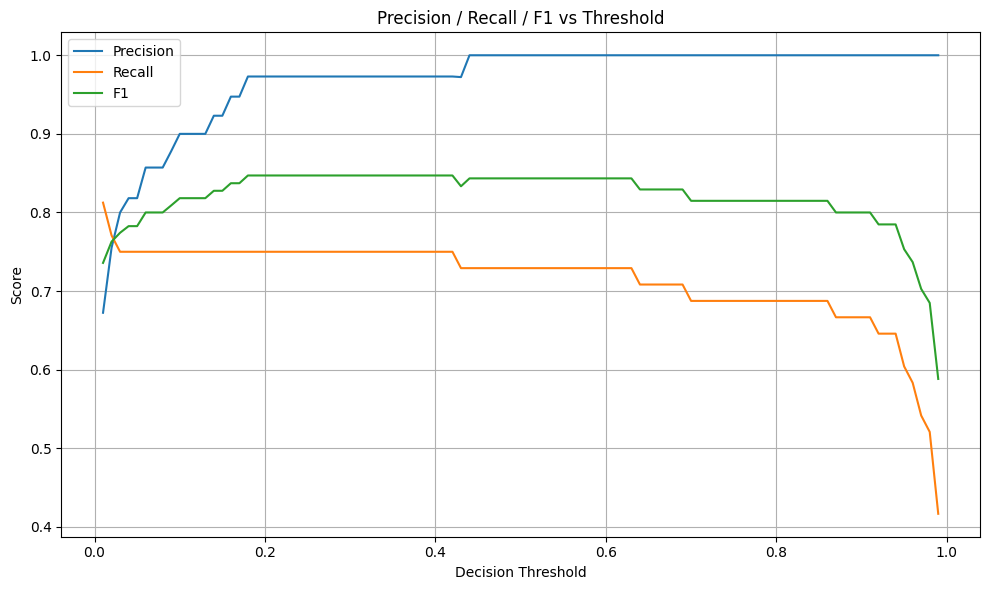

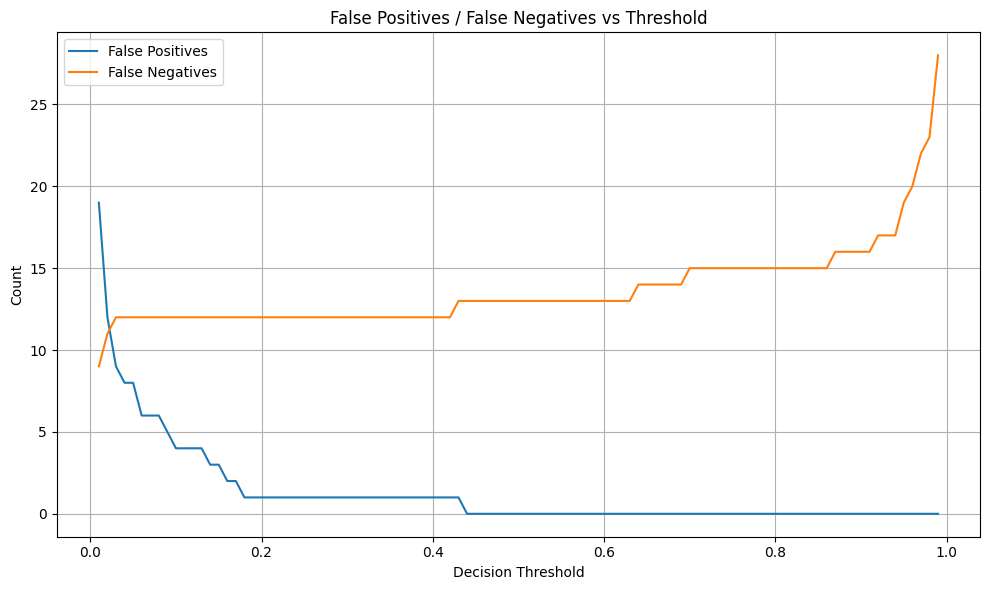


THRESHOLDS WITH PRECISION >= 95%


,Threshold,TP,FP,FN,Precision,Recall,F1
17,0.18,36,1,12,0.972973,0.750000,0.847059
18,0.19,36,1,12,0.972973,0.750000,0.847059
19,0.20,36,1,12,0.972973,0.750000,0.847059
20,0.21,36,1,12,0.972973,0.750000,0.847059
21,0.22,36,1,12,0.972973,0.750000,0.847059
...,...,...,...,...,...,...,...
94,0.95,29,0,19,1.000000,0.604167,0.753247
95,0.96,28,0,20,1.000000,0.583333,0.736842
96,0.97,26,0,22,1.000000,0.541667,0.702703
97,0.98,25,0,23,1.000000,0.520833,0.684932



THRESHOLDS WITH RECALL >= 80%


,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.01,39,19,9,0.672414,0.8125,0.735849



Threshold analysis saved.


In [86]:
# ============================================================
# STAGE 7 — THRESHOLD OPTIMIZATION
# Credit Card Fraud Detection
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ------------------------------------------------------------
# 1. USE BEST CURRENT MODEL
# ------------------------------------------------------------

# Baseline XGBoost currently has the highest PR-AUC
best_model = xgb_baseline

# Generate validation probabilities
threshold_proba = best_model.predict_proba(X_val)[:, 1]

print("=" * 70)
print("STAGE 7 — THRESHOLD OPTIMIZATION")
print("=" * 70)

print(f"Validation samples : {len(y_val)}")
print(f"Actual frauds      : {y_val.sum()}")
print(f"Fraud rate         : {y_val.mean() * 100:.4f}%")


# ------------------------------------------------------------
# 2. TEST MANY THRESHOLDS
# ------------------------------------------------------------

thresholds = np.arange(
    0.01,
    1.00,
    0.01
)

threshold_results = []

for threshold in thresholds:

    y_pred = (
        threshold_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred
    ).ravel()

    precision_t = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall_t = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1_t = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Precision": precision_t,
        "Recall": recall_t,
        "F1": f1_t
    })


threshold_df = pd.DataFrame(
    threshold_results
)


# ------------------------------------------------------------
# 3. BEST THRESHOLD BY F1
# ------------------------------------------------------------

best_f1_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("\n" + "=" * 70)
print("BEST THRESHOLD BY F1")
print("=" * 70)

print(
    best_f1_row.to_string()
)


# ------------------------------------------------------------
# 4. BEST THRESHOLD BY RECALL
#    SUBJECT TO PRECISION >= 90%
# ------------------------------------------------------------

precision_constraint = 0.90

eligible_recall = threshold_df[
    threshold_df["Precision"] >= precision_constraint
]

if len(eligible_recall) > 0:

    best_recall_row = eligible_recall.loc[
        eligible_recall["Recall"].idxmax()
    ]

    print("\n" + "=" * 70)
    print(
        f"BEST RECALL WITH PRECISION >= "
        f"{precision_constraint:.0%}"
    )
    print("=" * 70)

    print(
        best_recall_row.to_string()
    )

else:

    best_recall_row = None

    print(
        "\nNo threshold satisfies the "
        "precision constraint."
    )


# ------------------------------------------------------------
# 5. BEST THRESHOLD BY RECALL
#    SUBJECT TO PRECISION >= 95%
# ------------------------------------------------------------

precision_constraint_high = 0.95

eligible_high = threshold_df[
    threshold_df["Precision"] >= precision_constraint_high
]

if len(eligible_high) > 0:

    best_recall_high = eligible_high.loc[
        eligible_high["Recall"].idxmax()
    ]

    print("\n" + "=" * 70)
    print(
        f"BEST RECALL WITH PRECISION >= "
        f"{precision_constraint_high:.0%}"
    )
    print("=" * 70)

    print(
        best_recall_high.to_string()
    )

else:

    best_recall_high = None

    print(
        "\nNo threshold satisfies the "
        "high-precision constraint."
    )


# ------------------------------------------------------------
# 6. THRESHOLD = 0.50 REFERENCE
# ------------------------------------------------------------

default_row = threshold_df.iloc[
    np.argmin(
        np.abs(
            threshold_df["Threshold"] - 0.50
        )
    )
]

print("\n" + "=" * 70)
print("DEFAULT THRESHOLD = 0.50")
print("=" * 70)

print(
    default_row.to_string()
)


# ------------------------------------------------------------
# 7. DISPLAY IMPORTANT THRESHOLDS
# ------------------------------------------------------------

selected_thresholds = [
    0.01,
    0.05,
    0.10,
    0.15,
    0.20,
    0.25,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.90
]

threshold_table = threshold_df[
    threshold_df["Threshold"].round(2).isin(
        selected_thresholds
    )
].copy()

print("\n" + "=" * 70)
print("THRESHOLD TRADE-OFF TABLE")
print("=" * 70)

display(
    threshold_table[
        [
            "Threshold",
            "TP",
            "FP",
            "FN",
            "Precision",
            "Recall",
            "F1"
        ]
    ]
)


# ------------------------------------------------------------
# 8. PRECISION / RECALL / F1 CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision / Recall / F1 vs Threshold")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. FALSE POSITIVES / FALSE NEGATIVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FP"],
    label="False Positives"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FN"],
    label="False Negatives"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Count")
plt.title("False Positives / False Negatives vs Threshold")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. FIND ALL THRESHOLDS WITH HIGH PRECISION
# ------------------------------------------------------------

high_precision = threshold_df[
    threshold_df["Precision"] >= 0.95
]

print("\n" + "=" * 70)
print("THRESHOLDS WITH PRECISION >= 95%")
print("=" * 70)

if len(high_precision) > 0:

    display(
        high_precision[
            [
                "Threshold",
                "TP",
                "FP",
                "FN",
                "Precision",
                "Recall",
                "F1"
            ]
        ]
    )

else:

    print("None found.")


# ------------------------------------------------------------
# 11. FIND ALL THRESHOLDS WITH RECALL >= 80%
# ------------------------------------------------------------

high_recall = threshold_df[
    threshold_df["Recall"] >= 0.80
]

print("\n" + "=" * 70)
print("THRESHOLDS WITH RECALL >= 80%")
print("=" * 70)

if len(high_recall) > 0:

    display(
        high_recall[
            [
                "Threshold",
                "TP",
                "FP",
                "FN",
                "Precision",
                "Recall",
                "F1"
            ]
        ]
    )

else:

    print("No threshold reaches 80% recall.")


# ------------------------------------------------------------
# 12. SAVE THRESHOLD ANALYSIS
# ------------------------------------------------------------

threshold_df.to_csv(
    "threshold_analysis.csv",
    index=False
)

print("\nThreshold analysis saved.")

| Strategy       |     Threshold |  Precision |     Recall |        F1 |    FP |
| -------------- | ------------: | ---------: | ---------: | --------: | ----: |
| Aggressive     |          0.01 |     67.24% | **81.25%** |     0.736 |    19 |
| Balanced       |          0.10 |     90.00% |     75.00% |     0.818 |     4 |
| **F1-optimal** | **0.18–0.40** | **97.30%** | **75.00%** | **0.847** | **1** |
| Default        |          0.50 |       100% |     72.92% |     0.843 |     0 |
| Conservative   |          0.90 |       100% |     66.67% |     0.800 |     0 |


STAGE 8 — COST-SENSITIVE FRAUD DETECTION

The idea is different from Stage 7.

Stage 7 asked:

Which threshold gives the best statistical trade-off?

Stage 8 asks:

What happens if missing a fraud is much more expensive than investigating a genuine transaction?

We'll assign:

False Positive = investigation cost
False Negative = missed-fraud cost

Then calculate:

Cost=FP×C
FP
	​

+FN×C
FN
	​


In [87]:
# ================================================================
# STAGE 8 — COST-SENSITIVE FRAUD DETECTION
# ================================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

print("=" * 70)
print("STAGE 8 — COST-SENSITIVE FRAUD DETECTION")
print("=" * 70)

# ------------------------------------------------
# Use validation probabilities from baseline XGBoost
# ------------------------------------------------

val_proba = xgb_baseline.predict_proba(X_val)[:, 1]

# ------------------------------------------------
# Define cost scenarios
# ------------------------------------------------

cost_scenarios = {
    "Balanced": {
        "FP": 1,
        "FN": 5
    },
    "Fraud-sensitive": {
        "FP": 1,
        "FN": 10
    },
    "Highly-fraud-sensitive": {
        "FP": 1,
        "FN": 20
    }
}

thresholds = np.arange(0.01, 1.00, 0.01)

results = []

for scenario, costs in cost_scenarios.items():

    for threshold in thresholds:

        pred = (val_proba >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            pred,
            labels=[0, 1]
        ).ravel()

        cost = (
            fp * costs["FP"] +
            fn * costs["FN"]
        )

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0

        results.append({
            "Scenario": scenario,
            "Threshold": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "Precision": precision,
            "Recall": recall,
            "Cost": cost
        })

cost_df = pd.DataFrame(results)

# ------------------------------------------------
# Best threshold for every cost scenario
# ------------------------------------------------

for scenario in cost_scenarios:

    subset = cost_df[
        cost_df["Scenario"] == scenario
    ]

    best = subset.loc[
        subset["Cost"].idxmin()
    ]

    print("\n" + "=" * 70)
    print(f"SCENARIO: {scenario}")
    print("=" * 70)

    print(f"FP cost : {cost_scenarios[scenario]['FP']}")
    print(f"FN cost : {cost_scenarios[scenario]['FN']}")

    print(f"\nOptimal threshold : {best['Threshold']:.2f}")
    print(f"TP                 : {int(best['TP'])}")
    print(f"FP                 : {int(best['FP'])}")
    print(f"FN                 : {int(best['FN'])}")
    print(f"TN                 : {int(best['TN'])}")
    print(f"Precision          : {best['Precision']:.4f}")
    print(f"Recall             : {best['Recall']:.4f}")
    print(f"Total cost         : {best['Cost']:.2f}")

# ------------------------------------------------
# Save
# ------------------------------------------------

cost_df.to_csv(
    "stage8_cost_sensitive_results.csv",
    index=False
)

print("\nSaved: stage8_cost_sensitive_results.csv")

STAGE 8 — COST-SENSITIVE FRAUD DETECTION

SCENARIO: Balanced
FP cost : 1
FN cost : 5

Optimal threshold : 0.18
TP                 : 36
FP                 : 1
FN                 : 12
TN                 : 28324
Precision          : 0.9730
Recall             : 0.7500
Total cost         : 61.00

SCENARIO: Fraud-sensitive
FP cost : 1
FN cost : 10

Optimal threshold : 0.01
TP                 : 39
FP                 : 19
FN                 : 9
TN                 : 28306
Precision          : 0.6724
Recall             : 0.8125
Total cost         : 109.00

SCENARIO: Highly-fraud-sensitive
FP cost : 1
FN cost : 20

Optimal threshold : 0.01
TP                 : 39
FP                 : 19
FN                 : 9
TN                 : 28306
Precision          : 0.6724
Recall             : 0.8125
Total cost         : 199.00

Saved: stage8_cost_sensitive_results.csv


In [88]:
# ================================================================
# STAGE 9 — ADVANCED FEATURE ENGINEERING
# ================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STAGE 9 — ADVANCED FEATURE ENGINEERING")
print("=" * 70)

def engineer_features(df):

    X = df.copy()

    # ------------------------------------------------
    # Amount transformations
    # ------------------------------------------------

    X["LogAmount"] = np.log1p(X["Amount"])

    # ------------------------------------------------
    # Time transformations
    # ------------------------------------------------

    X["TimeHours"] = X["Time"] / 3600

    X["HourSin"] = np.sin(
        2 * np.pi * X["Hour"] / 24
    )

    X["HourCos"] = np.cos(
        2 * np.pi * X["Hour"] / 24
    )

    # ------------------------------------------------
    # PCA component statistics
    # ------------------------------------------------

    v_cols = [
        c for c in X.columns
        if c.startswith("V")
        and c[1:].isdigit()
    ]

    X["V_Mean"] = X[v_cols].mean(axis=1)
    X["V_Std"] = X[v_cols].std(axis=1)
    X["V_Min"] = X[v_cols].min(axis=1)
    X["V_Max"] = X[v_cols].max(axis=1)

    X["V_AbsMean"] = X[v_cols].abs().mean(axis=1)
    X["V_AbsMax"] = X[v_cols].abs().max(axis=1)
    X["V_L2"] = np.sqrt(
        (X[v_cols] ** 2).sum(axis=1)
    )

    # ------------------------------------------------
    # Amount interactions
    # ------------------------------------------------

    X["AmountPerHour"] = (
        X["Amount"] /
        (X["TimeHours"] + 1)
    )

    X["Amount_V_AbsMean"] = (
        X["Amount"] * X["V_AbsMean"]
    )

    return X


# ------------------------------------------------
# Apply to ORIGINAL split data
# ------------------------------------------------

X_train_fe = engineer_features(X_train)
X_val_fe = engineer_features(X_val)

print("Original features :", X_train.shape[1])
print("New features      :", X_train_fe.shape[1])
print("Added features    :", X_train_fe.shape[1] - X_train.shape[1])

print("\nNew feature names:")
print([
    c for c in X_train_fe.columns
    if c not in X_train.columns
])

# ------------------------------------------------
# Train XGBoost
# ------------------------------------------------

xgb_fe = XGBClassifier(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_fe.fit(
    X_train_fe,
    y_train
)

val_proba_fe = xgb_fe.predict_proba(X_val_fe)[:, 1]
val_pred_fe = (val_proba_fe >= 0.5).astype(int)

from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

tn, fp, fn, tp = confusion_matrix(
    y_val,
    val_pred_fe
).ravel()

print("\n" + "=" * 70)
print("FEATURE ENGINEERING RESULTS")
print("=" * 70)

print(confusion_matrix(y_val, val_pred_fe))

print(
    classification_report(
        y_val,
        val_pred_fe,
        digits=4
    )
)

print(
    "ROC-AUC :",
    roc_auc_score(y_val, val_proba_fe)
)

print(
    "PR-AUC  :",
    average_precision_score(y_val, val_proba_fe)
)

STAGE 9 — ADVANCED FEATURE ENGINEERING
Original features : 31
New features      : 44
Added features    : 13

New feature names:
['LogAmount', 'TimeHours', 'HourSin', 'HourCos', 'V_Mean', 'V_Std', 'V_Min', 'V_Max', 'V_AbsMean', 'V_AbsMax', 'V_L2', 'AmountPerHour', 'Amount_V_AbsMean']

FEATURE ENGINEERING RESULTS
[[28324     1]
 [   13    35]]
              precision    recall  f1-score   support

           0     0.9995    1.0000    0.9998     28325
           1     0.9722    0.7292    0.8333        48

    accuracy                         0.9995     28373
   macro avg     0.9859    0.8646    0.9165     28373
weighted avg     0.9995    0.9995    0.9995     28373

ROC-AUC : 0.9730560458958517
PR-AUC  : 0.8145817175279666


In [89]:
# ================================================================
# STAGE 10 — HYPERPARAMETER OPTIMIZATION
# ================================================================

!pip -q install optuna

import optuna
import numpy as np

from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score

print("=" * 70)
print("STAGE 10 — HYPERPARAMETER OPTIMIZATION")
print("=" * 70)

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 300, 1000
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 3, 10
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.15,
            log=True
        ),

        "subsample": trial.suggest_float(
            "subsample",
            0.6,
            1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.6,
            1.0
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight",
            1,
            20
        ),

        "gamma": trial.suggest_float(
            "gamma",
            0,
            5
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            1e-8,
            10,
            log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            1e-3,
            20,
            log=True
        ),

        "objective": "binary:logistic",
        "eval_metric": "aucpr",
        "random_state": 42,
        "n_jobs": -1
    }

    model = XGBClassifier(**params)

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    proba = model.predict_proba(X_val)[:, 1]

    return average_precision_score(
        y_val,
        proba
    )


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(
        seed=42
    )
)

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True
)

print("\n" + "=" * 70)
print("BEST RESULT")
print("=" * 70)

print("Best PR-AUC:", study.best_value)

print("\nBest parameters:")

for key, value in study.best_params.items():
    print(f"{key}: {value}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.4 MB/s eta 0:00:00


[I 2026-10-03 18:34:09,476] A new study created in memory with name: no-name-ce637a8f-19a7-4c9b-b29f-b1ec9bc93282


STAGE 10 — HYPERPARAMETER OPTIMIZATION


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-03 18:35:06,504] Trial 0 finished with value: 0.8077363147407749 and parameters: {'n_estimators': 562, 'max_depth': 10, 'learning_rate': 0.07259248719561363, 'subsample': 0.8394633936788146, 'colsample_bytree': 0.6624074561769746, 'min_child_weight': 4, 'gamma': 0.2904180608409973, 'reg_alpha': 0.6245760287469893, 'reg_lambda': 0.3849583075868115}. Best is trial 0 with value: 0.8077363147407749.
[I 2026-10-03 18:36:02,595] Trial 1 finished with value: 0.8019838072935221 and parameters: {'n_estimators': 796, 'max_depth': 3, 'learning_rate': 0.13826189316223852, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'min_child_weight': 4, 'gamma': 0.9170225492671691, 'reg_alpha': 5.472429642032198e-06, 'reg_lambda': 0.18071456341395586}. Best is trial 0 with value: 0.8077363147407749.
[I 2026-10-03 18:36:49,087] Trial 2 finished with value: 0.8040348644512045 and parameters: {'n_estimators': 602, 'max_depth': 5, 'learning_rate': 0.05243180891902853, 'subsampl

In [90]:
# ================================================================
# TRAIN FINAL OPTIMIZED VALIDATION MODEL
# ================================================================

best_params = study.best_params

best_xgb = XGBClassifier(
    **best_params,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

best_xgb.fit(
    X_train,
    y_train
)

optimized_val_proba = (
    best_xgb.predict_proba(X_val)[:, 1]
)

optimized_pr_auc = average_precision_score(
    y_val,
    optimized_val_proba
)

print("Optimized Validation PR-AUC:",
      optimized_pr_auc)

Optimized Validation PR-AUC: 0.8142461161013738


STAGE 11 — ANOMALY DETECTION

Now we deliberately change paradigms.

Until now:

Supervised learning: learn X → fraud label

Now:

Unsupervised/semi-supervised learning: learn what "normal" looks like.

We'll test:

Isolation Forest
One-Class SVM

But don't expect them automatically to beat XGBoost.

In [91]:
# ================================================================
# STAGE 11 — ANOMALY DETECTION
# ================================================================

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

print("=" * 70)
print("STAGE 11 — ANOMALY DETECTION")
print("=" * 70)

# ------------------------------------------------
# Train ONLY on genuine transactions
# ------------------------------------------------

normal_mask = y_train == 0

X_train_normal = X_train.loc[normal_mask]

print("Normal training samples:",
      len(X_train_normal))

# ------------------------------------------------
# Isolation Forest
# ------------------------------------------------

iso = IsolationForest(
    n_estimators=300,
    contamination="auto",
    max_samples="auto",
    random_state=42,
    n_jobs=-1
)

iso.fit(X_train_normal)

# IsolationForest:
# lower score = more anomalous
# therefore negate it

val_anomaly_score = -iso.score_samples(
    X_val
)

print("\nIsolation Forest")
print("----------------")

print(
    "ROC-AUC:",
    roc_auc_score(
        y_val,
        val_anomaly_score
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_val,
        val_anomaly_score
    )
)

STAGE 11 — ANOMALY DETECTION
Normal training samples: 226602

Isolation Forest
----------------
ROC-AUC: 0.9195689908796705
PR-AUC: 0.08755715300163627


In [92]:
# ================================================================
# STAGE 12 — ENSEMBLE FRAUD DETECTOR
# ================================================================

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import average_precision_score

print("=" * 70)
print("STAGE 12 — ENSEMBLE FRAUD DETECTOR")
print("=" * 70)

# ------------------------------------------------
# XGBoost score
# ------------------------------------------------

xgb_score = optimized_val_proba

# ------------------------------------------------
# Normalize anomaly score
# ------------------------------------------------

scaler = MinMaxScaler()

anomaly_score_norm = scaler.fit_transform(
    val_anomaly_score.reshape(-1, 1)
).ravel()

# ------------------------------------------------
# Test ensemble weights
# ------------------------------------------------

weights = np.arange(
    0.0,
    1.01,
    0.05
)

ensemble_results = []

for w in weights:

    ensemble_score = (
        w * xgb_score
        +
        (1 - w) * anomaly_score_norm
    )

    pr_auc = average_precision_score(
        y_val,
        ensemble_score
    )

    ensemble_results.append({
        "XGB_Weight": w,
        "Anomaly_Weight": 1 - w,
        "PR_AUC": pr_auc
    })

ensemble_df = pd.DataFrame(
    ensemble_results
)

best_ensemble = ensemble_df.loc[
    ensemble_df["PR_AUC"].idxmax()
]

print("\nBest ensemble:")
print(best_ensemble)

print("\nBaseline XGB PR-AUC:",
      average_precision_score(
          y_val,
          xgb_score
      ))

print(
    "Best ensemble PR-AUC:",
    best_ensemble["PR_AUC"]
)

ensemble_df.to_csv(
    "stage12_ensemble_results.csv",
    index=False
)

STAGE 12 — ENSEMBLE FRAUD DETECTOR

Best ensemble:
XGB_Weight        1.000000
Anomaly_Weight    0.000000
PR_AUC            0.814246
Name: 20, dtype: float64

Baseline XGB PR-AUC: 0.8142461161013738
Best ensemble PR-AUC: 0.8142461161013738


What you're looking for

If:

ensemble PR-AUC > XGB PR-AUC

then anomaly detection contributes complementary information.

If not, that's still an important finding.

EXPLAINABILITY + ERROR ANALYSIS

This is one of the most important stages.

Instead of asking:

"What is my accuracy?"

we ask:

"Why does the model make mistakes?"

We'll analyze:

False positives
False negatives
highest-confidence fraud
highest-confidence genuine
feature importance
SHAP explanations

STAGE 13 — EXPLAINABILITY + ERROR ANALYSIS

Error counts:
ErrorType
Correct           28358
False Negative       12
False Positive        3
Name: count, dtype: int64

False positives:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Hour,Actual,Probability,Prediction,ErrorType
274771,166198.0,-35.548539,-31.850484,-48.325589,15.304184,-113.743307,73.301626,120.589494,-27.347360,-3.872425,...,4.554683,3.415636,31.612198,-15.430084,25691.16,22.166111,0,0.732557,1,False Positive
187657,127631.0,1.813886,0.381837,-4.023519,1.046436,1.584362,-0.344732,0.177102,0.088170,1.196258,...,0.653695,-0.187299,0.064843,0.069528,107.50,11.453056,0,0.301453,1,False Positive
8625,11641.0,-0.504072,3.923139,-5.850403,3.445290,5.058796,1.713523,0.875245,1.266811,-1.786064,...,1.059154,0.406180,-0.263793,-0.081023,1.00,3.233611,0,0.223002,1,False Positive



False negatives:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Hour,Actual,Probability,Prediction,ErrorType
68633,53076.0,1.296231,0.417447,0.193963,0.901644,0.130531,-0.371634,0.158126,-0.202669,-0.079512,...,0.671540,-0.413518,0.032838,0.020600,1.18,14.743333,1,6.642469e-07,0,False Negative
72757,54846.0,-2.986466,-0.000891,0.605887,0.338338,0.685448,-1.581954,0.504206,-0.233403,0.636768,...,0.448552,0.193490,1.214588,-0.013923,1.79,15.235000,1,3.170868e-06,0,False Negative
274382,165981.0,-5.766879,-8.402154,0.056543,6.950983,9.880564,-5.773192,-5.748879,0.721743,-1.076274,...,-1.890041,-0.120803,0.073269,0.583799,0.00,22.105833,1,1.401904e-05,0,False Negative
52521,45501.0,1.001992,0.047938,-0.349002,1.493958,0.186939,0.190966,-0.001112,0.147140,0.580415,...,0.456090,-0.453206,0.046627,0.064698,105.99,12.639167,1,1.585032e-05,0,False Negative
249239,154309.0,-0.082983,-3.935919,-2.616709,0.163310,-1.400952,-0.809419,1.501580,-0.471000,1.519743,...,-0.071622,-1.125881,-0.170947,0.126221,1096.99,18.863611,1,3.013820e-05,0,False Negative
101509,67857.0,-1.739334,-1.304655,0.314103,0.053740,-0.058696,0.071260,0.694862,-0.313270,-0.649377,...,-0.001640,-0.495162,0.031633,0.066280,320.00,18.849167,1,1.151764e-04,0,False Negative
58761,48533.0,1.243848,0.524526,-0.538884,1.209196,0.479538,-0.197429,0.049166,0.037792,0.128119,...,0.681953,-0.194419,0.045917,0.040136,1.00,13.481389,1,2.222444e-04,0,False Negative
154286,101051.0,-1.465316,-1.093377,-0.059768,1.064785,11.095089,-5.430971,-9.378025,-0.446456,1.992110,...,-3.536716,-0.592965,0.675525,0.424849,0.92,4.069722,1,4.117407e-04,0,False Negative
68067,52814.0,-1.101847,-1.632441,0.901067,0.847753,-1.249091,0.654937,1.448868,0.023308,-0.136742,...,-0.300896,0.699175,-0.336072,-0.177587,519.90,14.670556,1,6.156416e-03,0,False Negative
240222,150494.0,1.852889,1.069593,-1.776101,4.617410,0.770413,-0.400859,-0.040970,0.089510,-0.217705,...,0.058063,0.148263,0.042278,0.040573,1.00,17.803889,1,3.002477e-02,0,False Negative



Generating SHAP summary...


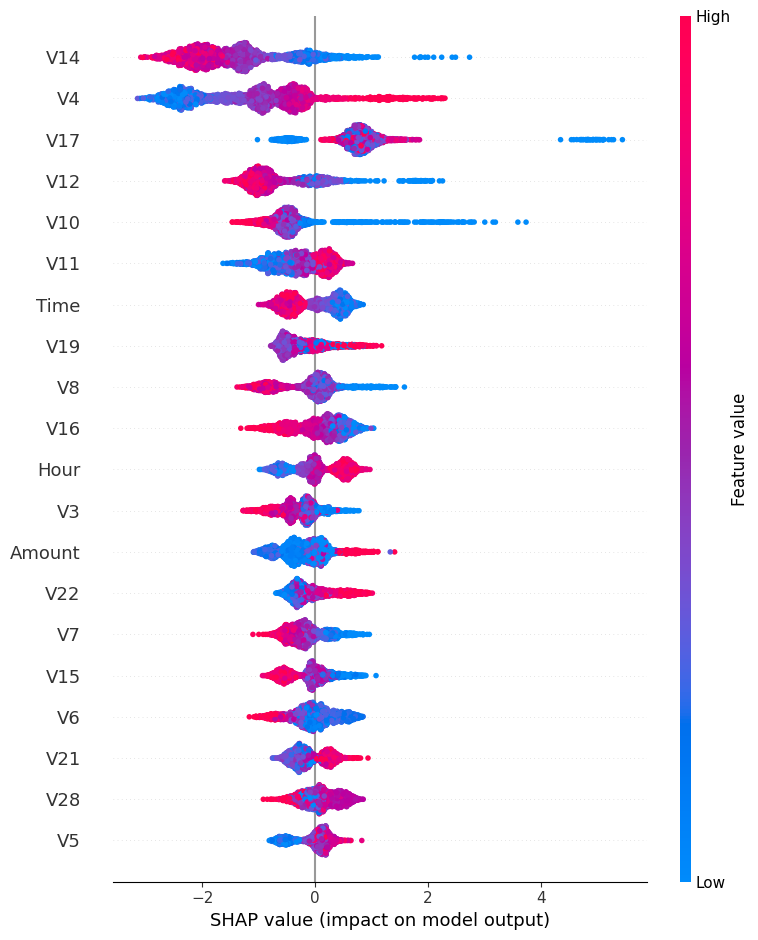

In [93]:
# ================================================================
# STAGE 13 — EXPLAINABILITY + ERROR ANALYSIS
# ================================================================

!pip -q install shap

import shap
import numpy as np
import pandas as pd

print("=" * 70)
print("STAGE 13 — EXPLAINABILITY + ERROR ANALYSIS")
print("=" * 70)

# ------------------------------------------------
# Choose current best supervised model
# ------------------------------------------------

final_validation_proba = optimized_val_proba

threshold = 0.18

final_validation_pred = (
    final_validation_proba >= threshold
).astype(int)

# ------------------------------------------------
# Error analysis
# ------------------------------------------------

error_df = X_val.copy()

error_df["Actual"] = y_val.values
error_df["Probability"] = final_validation_proba
error_df["Prediction"] = final_validation_pred

error_df["ErrorType"] = "Correct"

error_df.loc[
    (error_df["Actual"] == 0) &
    (error_df["Prediction"] == 1),
    "ErrorType"
] = "False Positive"

error_df.loc[
    (error_df["Actual"] == 1) &
    (error_df["Prediction"] == 0),
    "ErrorType"
] = "False Negative"

print("\nError counts:")
print(
    error_df["ErrorType"].value_counts()
)

# ------------------------------------------------
# False positives
# ------------------------------------------------

false_positives = error_df[
    error_df["ErrorType"] == "False Positive"
].sort_values(
    "Probability",
    ascending=False
)

print("\nFalse positives:")
display(
    false_positives.head(10)
)

# ------------------------------------------------
# False negatives
# ------------------------------------------------

false_negatives = error_df[
    error_df["ErrorType"] == "False Negative"
].sort_values(
    "Probability",
    ascending=True
)

print("\nFalse negatives:")
display(
    false_negatives.head(10)
)

# ------------------------------------------------
# SHAP
# ------------------------------------------------

sample_size = min(
    3000,
    len(X_val)
)

X_shap = X_val.sample(
    sample_size,
    random_state=42
)

explainer = shap.TreeExplainer(
    best_xgb
)

shap_values = explainer.shap_values(
    X_shap
)

print("\nGenerating SHAP summary...")

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20
)

PRODUCTION ML PIPELINE

Now we stop treating the notebook as the final product.

Create a reproducible pipeline:

Raw Transaction
      ↓
Validation
      ↓
Feature Engineering
      ↓
Model
      ↓
Probability
      ↓
Threshold
      ↓
Fraud / Genuine
      ↓
Logging

We'll create a simple production-style predictor.

In [94]:
# ================================================================
# STAGE 14 — PRODUCTION INFERENCE PIPELINE
# ================================================================

import joblib
import numpy as np
import pandas as pd

print("=" * 70)
print("STAGE 14 — PRODUCTION INFERENCE PIPELINE")
print("=" * 70)

class FraudDetector:

    def __init__(
        self,
        model,
        threshold=0.18
    ):

        self.model = model
        self.threshold = threshold

    def predict(self, X):

        probability = self.model.predict_proba(
            X
        )[:, 1]

        prediction = (
            probability >= self.threshold
        ).astype(int)

        result = X.copy()

        result["fraud_probability"] = probability

        result["prediction"] = prediction

        result["decision"] = np.where(
            prediction == 1,
            "FRAUD_REVIEW",
            "GENUINE"
        )

        return result


# ------------------------------------------------
# Create detector
# ------------------------------------------------

detector = FraudDetector(
    model=best_xgb,
    threshold=0.18
)

# ------------------------------------------------
# Example inference
# ------------------------------------------------

sample = X_val.iloc[:10]

result = detector.predict(sample)

display(result[
    [
        "fraud_probability",
        "prediction",
        "decision"
    ]
])

# ------------------------------------------------
# Save model
# ------------------------------------------------

joblib.dump(
    best_xgb,
    "fraud_xgboost_model.pkl"
)

joblib.dump(
    detector,
    "fraud_detector.pkl"
)

print("\nSaved:")
print("fraud_xgboost_model.pkl")
print("fraud_detector.pkl")

STAGE 14 — PRODUCTION INFERENCE PIPELINE


,fraud_probability,prediction,decision
211222,7.862823e-07,0,GENUINE
201517,2.675807e-07,0,GENUINE
60458,4.446404e-07,0,GENUINE
248110,2.940977e-06,0,GENUINE
122472,1.510632e-06,0,GENUINE
132740,2.785919e-04,0,GENUINE
265839,1.768568e-07,0,GENUINE
7463,1.093622e-06,0,GENUINE
139954,4.870640e-04,0,GENUINE
24499,4.835178e-06,0,GENUINE



Saved:
fraud_xgboost_model.pkl
fraud_detector.pkl


MONITORING + DRIFT DETECTION

A model isn't finished when you deploy it.

Suppose six months later:

Transaction patterns change
        ↓
Feature distribution changes
        ↓
Model confidence changes
        ↓
Fraud detection degrades

We need monitoring.

We'll compare train vs validation distributions.

In [95]:
# ================================================================
# STAGE 15 — MODEL MONITORING + DRIFT
# ================================================================

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp

print("=" * 70)
print("STAGE 15 — MODEL MONITORING + DRIFT DETECTION")
print("=" * 70)

drift_results = []

for column in X_train.columns:

    train_values = X_train[column].dropna()
    current_values = X_val[column].dropna()

    statistic, p_value = ks_2samp(
        train_values,
        current_values
    )

    drift_results.append({
        "Feature": column,
        "KS_Statistic": statistic,
        "P_Value": p_value
    })

drift_df = pd.DataFrame(
    drift_results
)

drift_df = drift_df.sort_values(
    "KS_Statistic",
    ascending=False
)

print("\nTop potential distribution shifts:")
display(
    drift_df.head(15)
)

drift_df.to_csv(
    "stage15_drift_report.csv",
    index=False
)

print(
    "\nSaved: stage15_drift_report.csv"
)

STAGE 15 — MODEL MONITORING + DRIFT DETECTION

Top potential distribution shifts:


,Feature,KS_Statistic,P_Value
21,V21,0.009988,0.012967
19,V19,0.009546,0.020054
11,V11,0.009148,0.029173
29,Amount,0.007983,0.079920
28,V28,0.007931,0.083307
23,V23,0.007564,0.111048
3,V3,0.006286,0.270746
13,V13,0.006162,0.292559
25,V25,0.006125,0.299159
1,V1,0.006060,0.311222



Saved: stage15_drift_report.csv


In [96]:
# ================================================================
# FINAL EVALUATION — TEST SET
# ================================================================

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------
# IMPORTANT:
# Use the exact feature representation used by
# the selected model.
# ------------------------------------------------

test_proba = best_xgb.predict_proba(
    X_test
)[:, 1]

# ------------------------------------------------
# Frozen threshold
# ------------------------------------------------

FINAL_THRESHOLD = 0.18

test_pred = (
    test_proba >= FINAL_THRESHOLD
).astype(int)

# ------------------------------------------------
# Metrics
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred
).ravel()

precision = (
    tp / (tp + fp)
    if (tp + fp) > 0
    else 0
)

recall = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else 0
)

f1 = (
    2 * precision * recall /
    (precision + recall)
    if precision + recall > 0
    else 0
)

roc_auc = roc_auc_score(
    y_test,
    test_proba
)

pr_auc = average_precision_score(
    y_test,
    test_proba
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        test_pred
    )
)

print("\nTP :", tp)
print("FP :", fp)
print("FN :", fn)
print("TN :", tn)

print("\nPrecision :", precision)
print("Recall    :", recall)
print("F1        :", f1)
print("ROC-AUC   :", roc_auc)
print("PR-AUC    :", pr_auc)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_pred,
        digits=4
    )
)

FINAL TEST EVALUATION

Confusion Matrix:
[[28324     2]
 [    9    38]]

TP : 38
FP : 2
FN : 9
TN : 28324

Precision : 0.95
Recall    : 0.8085106382978723
F1        : 0.8735632183908046
ROC-AUC   : 0.9858741912174516
PR-AUC    : 0.8476260715655435

Classification Report:
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     28326
           1     0.9500    0.8085    0.8736        47

    accuracy                         0.9996     28373
   macro avg     0.9748    0.9042    0.9367     28373
weighted avg     0.9996    0.9996    0.9996     28373



In [97]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

# Change this folder name if you want
DRIVE_FOLDER = "/content/drive/MyDrive/Fraud_Detection_Project"

os.makedirs(DRIVE_FOLDER, exist_ok=True)

# Copy everything from /content into the Drive folder
for item in os.listdir("/content"):
    src = os.path.join("/content", item)

    # Don't copy the Drive mount into itself
    if item == "drive":
        continue

    dst = os.path.join(DRIVE_FOLDER, item)

    try:
        if os.path.isdir(src):
            if os.path.exists(dst):
                shutil.copytree(src, dst, dirs_exist_ok=True)
            else:
                shutil.copytree(src, dst)
        else:
            shutil.copy2(src, dst)
    except Exception as e:
        print(f"Skipped {item}: {e}")

print("✅ Everything saved to:")
print(DRIVE_FOLDER)

Mounted at /content/drive
✅ Everything saved to:
/content/drive/MyDrive/Fraud_Detection_Project


In [98]:
!du -sh "/content/drive/MyDrive/Fraud_Detection_Project"
!find "/content/drive/MyDrive/Fraud_Detection_Project" -maxdepth 2 -type f | head -50

341M	/content/drive/MyDrive/Fraud_Detection_Project
/content/drive/MyDrive/Fraud_Detection_Project/.config/config_sentinel
/content/drive/MyDrive/Fraud_Detection_Project/.config/gce
/content/drive/MyDrive/Fraud_Detection_Project/.config/.last_opt_in_prompt.yaml
/content/drive/MyDrive/Fraud_Detection_Project/.config/.last_survey_prompt.yaml
/content/drive/MyDrive/Fraud_Detection_Project/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/drive/MyDrive/Fraud_Detection_Project/.config/active_config
/content/drive/MyDrive/Fraud_Detection_Project/.config/default_configs.db
/content/drive/MyDrive/Fraud_Detection_Project/.config/.last_update_check.json
/content/drive/MyDrive/Fraud_Detection_Project/stage12_ensemble_results.csv
/content/drive/MyDrive/Fraud_Detection_Project/fraud_xgboost_model.pkl
/content/drive/MyDrive/Fraud_Detection_Project/fraud_scaler.pkl
/content/drive/MyDrive/Fraud_Detection_Project/creditcardfraud.zip
/content/drive/MyDrive/Fraud_Detection_P